# Collecting scored attempts to train a small model

## Learning by trying

One way to improve a language model is to let it practise. The model tries a task, a program checks the result, and the model is then adjusted so that it becomes more likely to repeat what it did in its better tries. Done over many tasks and many tries, this is called reinforcement learning. [DeepSeekMath](https://arxiv.org/abs/2402.03300) is one published example: its authors used it to improve a model's maths answers.

Practice of this kind needs two things before any training starts. The first is a program that sets the task, accepts the model's moves and scores them. Such a program is called an environment. The second is a record of every try: what the model was shown, what it chose, what happened next and how each step was scored. Training papers call one recorded try a rollout. This page calls it an attempt.

A useful collection is a set of attempts whose scores can be trusted and which separate better tries from worse ones. Collecting it costs model calls, and a team pays that cost before it learns whether the attempts will teach the model anything. This experiment is about that collection step. It trains no model.

### A small maze (illustrative)

Here is a made-up case that uses the real scoring rules of the maze environment in this study. A model is shown a 4 by 4 grid with a few walls. It starts in one square, and the exit is two squares away: one square up, then one square to the right. On each turn the model names one direction. The environment moves it, or reports a wall and leaves it where it was.

The environment scores every move. An ordinary move into a new square costs 0.05 points, and reaching the exit earns 10. The two-move route therefore scores -0.05 + 10 = 9.95. These per-move scores are the step rewards. If the model first walks into a wall, that bump costs 0.75, and the same route then totals 9.20.

There is also a simpler question: did the model reach the exit within ten moves? The answer is recorded as 1 or 0 and is called the outcome. Both routes above have outcome 1. A model that walks into the same wall ten times in a row has outcome 0, whatever its step rewards add up to. In this study the outcome decides success; the step rewards are kept beside it.

### Why a group of attempts needs both a success and a failure

The training methods this collection prepares for learn by comparison. The model tries the same maze four times. Suppose one try reaches the exit and three do not, so the outcomes are 0, 0, 1, 0. Their average is 0.25. The successful try is above the average, so a trainer would make its choices more likely. The three failures are below it, so their choices would become less likely.

Now suppose all four tries fail: 0, 0, 0, 0. Every try equals the average, and there is nothing to push towards. The same is true when all four succeed. Those four attempts cost model calls and teach nothing under this rule. This page calls a group of four attempts at one task a **mixed group** when it holds at least one success and at least one failure. The number of mixed groups is the measure of how useful a collection is.

### Why collection can be wasteful

A maze attempt can take ten model calls, one per move. A question takes one. A small model that almost never finds a maze exit produces group after group of four failures, so most of the calls spent on mazes buy nothing. A model that answers an easy question right every time wastes calls in the other direction. The tasks worth collecting are the ones the model solves some of the time.

### Two ways to spend less

The plain approach is to give every task the same number of tries, here four. It is easy to run and easy to check, and it spends as much on hopeless tasks as on useful ones.

The first alternative is to stop early. Watch the first few tries at a task. If the first three all fail, or all succeed, skip the fourth, on the reasoning that it is unlikely to differ. This saves calls, but it can throw away a group whose fourth try would have been its first success.

The second alternative is to choose where the next round of tries goes. After a first round, give more tries to tasks whose results so far suggest the model solves them some of the time, and prefer cheap tasks (one call) over expensive ones (up to ten calls). This could find more mixed groups for the same spend, or it could chase noise in four results.

A team that plans to train a small model needs to know whether that model produces mixed groups at all on its tasks, and whether either shortcut keeps them while spending less. On 28 September 2026 Hugging Face [made such environments easy to find on its Hub](https://huggingface.co/blog/rl-environments), and several 2026 papers proposed stopping and choosing rules for large training runs. This experiment tries those rules at small scale, with two small models, on tasks generated for the experiment so that every answer can be checked exactly.

## The question

Two small open-weight models (models whose trained weights are published, so anyone can run or train them), Llama 3.2 3B and Gemma 3 4B, each make four scored attempts at 8 freshly generated tasks: 4 mazes and 4 questions (two arithmetic expressions and two lists of words to reverse). How many of these groups of four contain both a success and a failure, which is what training by comparison needs? And would stopping a task once its first attempts agree, or choosing second-round tasks from the first round's scores, find those groups with fewer model calls?

## Study summary

Each model made four attempts at each of the 8 tasks, which gives 16 groups and 64 attempts in a first round. A second round spent 16 more attempts on 4 tasks chosen from the first round's scores. That is 80 attempts and 336 model calls in all. Every reply that came back could be read and scored; 6 Llama attempts got no reply because the provider rate-limited the requests, which left 3 of Llama's 8 first-round groups incomplete.

Only **2 of the 13 complete first-round groups** were mixed, both from Llama (`maze-01` and `reason-03`). Mazes were the main obstacle: 1 of 29 scored maze attempts reached the exit, against 11 of 30 question attempts. Gemma's maze results sit at the floor (0 of 16), and in 7 of its 8 groups its four attempts were identical, move for move or word for word, so repeating a task gave it no contrast at all.

Replayed on the saved attempts, the early-stop rule would have used 193 of the 261 calls spent on complete groups (26% fewer) and kept both mixed groups. With four tries per task, the rule amounts to skipping the fourth try when the first three agree. The score-guided second round chose four question tasks; of the 3 groups that finished complete, none was mixed.

In the original situation: most of what a small model's practice cost here went on groups that would teach a trainer nothing, above all maze attempts it never solved (288 of the 336 calls bought 1 success). Skipping obvious repeats saves about a quarter of the calls; the larger need is tasks the model solves some of the time, and attempts that actually differ from each other.

The main caveat is size: eight tasks and two models give counts too small to rank the collection plans, and the early-stop saving is a replay on attempts that were all collected and paid for.

## Contents

1. [Setup and size settings](#1.-Setup-and-size-settings)
2. [Where the environments come from](#2.-Where-the-environments-come-from)
3. [The eight tasks and how answers are checked](#3.-The-eight-tasks-and-how-answers-are-checked)
4. [How an attempt runs and the two models](#4.-How-an-attempt-runs-and-the-two-models)
5. [The measure and the collection plans](#5.-The-measure-and-the-collection-plans)
6. [Collecting the attempts](#6.-Collecting-the-attempts)
7. [Successes and groups with both outcomes](#7.-Successes-and-groups-with-both-outcomes)
8. [Stopping early and choosing second-round tasks](#8.-Stopping-early-and-choosing-second-round-tasks)
9. [Worked examples and error analysis](#9.-Worked-examples-and-error-analysis)
10. [Saved records and spend](#10.-Saved-records-and-spend)
11. [What the evidence supports](#11.-What-the-evidence-supports)
12. [Limitations](#12.-Limitations)
13. [How to reproduce](#13.-How-to-reproduce)
14. [Future work and further reading](#14.-Future-work-and-further-reading)

### How the study runs

```mermaid
flowchart TD
    T["8 tasks generated in code on 2026-10-24<br/>4 mazes + 4 questions, answers known"] --> E["OpenEnv maze and Reasoning Gym environments, run locally<br/>8 of 8 tasks solved with the known answer first"]
    E --> R1["First round, fixed plan<br/>2 models x 8 tasks x 4 attempts = 64 attempts<br/>320 model calls through OpenRouter"]
    R1 --> G["16 groups: 13 complete, 3 incomplete<br/>(5 Llama attempts got no reply, HTTP 429)<br/>2 mixed groups"]
    G --> STOP["Early-stop rule replayed on the 13 complete groups<br/>193 of 261 calls, 2 of 2 mixed groups kept"]
    G --> COV["Coverage bonus on the 5 all-failed maze groups<br/>gives scores to 1"]
    G --> PICK["Score-guided choice<br/>2 question tasks per model"]
    PICK --> R2["Second round: 4 tasks x 4 attempts = 16 attempts, 16 calls<br/>1 no reply; 3 complete groups, 0 mixed"]
    STOP --> OUT["80 saved attempts with step rewards, outcomes and scores<br/>no model trained"]
    COV --> OUT
    R2 --> OUT
```

One task shows the whole path. Llama's four attempts at `maze-01` (the first maze) are scored by the environment move by move; their outcomes 0, 0, 1, 0 make a mixed group. The early-stop rule, replayed on them, keeps the group after the third attempt. The score-guided choice gives the task a low chance of a second round because a maze attempt costs up to ten calls, and does not pick it. Section 5 walks through this example with the actual replies and numbers.

## 1. Setup and size settings

This cell loads the libraries and sets the size of the study. Everything that costs money has a setting here: 4 mazes and 4 questions (`N_MAZES`, `N_REASONING`), 4 attempts per group (`N_ROLLOUTS`), 2 second-round tasks per model (`N_RIDGE_TASKS`) and at most 10 moves per maze (`MAX_STEPS`). Three caps stop a new collection before it sends a request that would pass 96 attempts, 600 requests or $2 of spend. The two models, their pinned providers, the sampling temperature (0.9) and the settings of the early-stop rule and the coverage bonus are fixed here too; Section 5 explains them.

By default the notebook replays saved responses and makes no network request. `NB_LIVE=1` allows new requests; it never trains a model. All helper functions are defined inside this notebook. The printed line should report replay mode, 8 tasks, 80 planned attempts and 0 model weight updates.

In [1]:
from pathlib import Path
from collections import deque, Counter
from contextlib import ExitStack
from datetime import datetime
from zoneinfo import ZoneInfo
import ast
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import re
import socket
import threading
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

LIVE = os.environ.get("NB_LIVE") == "1"
MODELS = ["meta-llama/llama-3.2-3b-instruct", "google/gemma-3-4b-it"]
N_MAZES = 4
N_REASONING = 4
N_ROLLOUTS = 4
N_RIDGE_TASKS = 2
MAX_STEPS = 10
MAX_EPISODES = 96
MAX_REQUESTS = 600
MAX_SPEND_USD = 2.0
TEMPERATURE = 0.9
SARA_PROBE = 2
SARA_ABANDON = 0.30
COVERAGE_SCALE = 0.25
COVERAGE_MIN_STD = 1e-6
PROTOCOL = "openenv-rewards-v1.1"
PROVIDERS = {MODELS[0]: "Parasail", MODELS[1]: "DeepInfra"}
OPENENV_REVISION = "21fbb0ecb2a3e74110b59cf38a1b195decc75c88"
DATA, FIGURES = Path("data"), Path("figures")
CACHE = DATA / "cache"
for folder in (DATA, CACHE, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
assert N_ROLLOUTS == 4, "The saved SARA audit uses a four-attempt cap."
assert len(MODELS) * (N_MAZES + N_REASONING + N_RIDGE_TASKS) * N_ROLLOUTS <= MAX_EPISODES

# One style block for every figure in this notebook.
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 180,
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.20})
COLOURS = {MODELS[0]: "#1f618d", MODELS[1]: "#b45309"}
LABELS = {MODELS[0]: "Llama 3.2 3B", MODELS[1]: "Gemma 3 4B"}

def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False)

def digest(value):
    return hashlib.sha256(canonical(value).encode("utf-8")).hexdigest()

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n", encoding="utf-8", newline="\n")

def write_jsonl(path, rows):
    path.write_text("".join(canonical(row) + "\n" for row in rows), encoding="utf-8", newline="\n")

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line]

print({"mode": "live" if LIVE else "offline model-response replay",
       "tasks": N_MAZES + N_REASONING, "planned_episodes": 80,
       "request_limit": MAX_REQUESTS, "dollar_ceiling": MAX_SPEND_USD,
       "model_weight_updates": 0})

{'mode': 'offline model-response replay', 'tasks': 8, 'planned_episodes': 80, 'request_limit': 600, 'dollar_ceiling': 2.0, 'model_weight_updates': 0}


## 2. Where the environments come from

On 28 September 2026 Hugging Face published [Welcome RL Environments to the hub](https://huggingface.co/blog/rl-environments) (Burtenshaw et al.), which lets dataset pages on its Hub be tagged as environments so they can be found and loaded. The Hub stores the task collections; a separate library runs them. [OpenEnv](https://github.com/huggingface/OpenEnv/tree/v0.10.0) is one such library, alongside others the post names (Harbor, Verifiers, NeMo Gym).

This study uses the official maze and Reasoning Gym environments from OpenEnv 0.10.0, but generates its own eight tasks with them (Section 3) instead of scoring a Hub benchmark, so that every task is newer than both models. The cell below loads a frozen page of the Hub listing, saved when the study ran, and shows the first entries tagged `openenv`. It is a record of what could be found, not something the study uses.

In [2]:
hub = json.loads((DATA / "hub_catalogue.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{"dataset": x["id"],
    "openenv_tag": "openenv" in x.get("tags", [])}
    for x in hub if "openenv" in x.get("tags", [])]).head(6))
print("Frozen discovery page:", len(hub), "entries; not a complete Hub census")

,dataset,openenv_tag
0,reasoning-core/procedural-pile,True
1,Akahsizrr/quant-desk,True
2,d0rj/chgk,True
3,Prasham1710/ci-triage-scenarios,True
4,yatin-superintelligence/blood-pathology-lims-e...,True
5,yatin-superintelligence/digital-hospital-envir...,True


Frozen discovery page: 200 entries; not a complete Hub census


The frozen page holds 200 Hub entries, and 43 of them carry the `openenv` tag (counted from `data/hub_catalogue.json`, field `tags`). The six shown range from a puzzle collection (`reasoning-core/procedural-pile`) to made-up hospital and trading-desk scenarios. A tag only says a dataset can be found as an environment; it does not say which library loads it or how its answers are scored, which is one reason this study builds its tasks itself.

## 3. The eight tasks and how answers are checked

The tasks were generated in code with fixed seeds on 24 October 2026 and frozen in `data/tasks.json`, each with a hash so a re-run scores the same items. Mazes have walls placed at random and routes of 2, 4, 6 and 8 moves. The questions come from Reasoning Gym, a library of generated puzzles with checkable answers.

| Task | What the model is asked | Correct answer | Model calls per attempt |
|---|---|---|---|
| `maze-01` | 4 by 4 map, start `[0,1]`, exit `[1,0]` | Shortest route 2 moves (up, right) | Up to 10 |
| `maze-02` | 4 by 4 map, start `[1,2]`, exit `[3,0]` | Shortest route 4 moves | Up to 10 |
| `maze-03` | 5 by 5 map, start `[4,3]`, exit `[0,3]` | Shortest route 6 moves | Up to 10 |
| `maze-04` | 5 by 5 map, start `[0,3]`, exit `[1,0]` | Shortest route 8 moves | Up to 10 |
| `reason-01` | `Calculate 2 - 40.` | `-38` | 1 |
| `reason-02` | `Calculate ( 551 * -29 ) + ( -355 * 717 - 71 ) * 164.` | `-41771363` | 1 |
| `reason-03` | Reverse the list `it, in, say, the, stress, copies` | `copies, stress, the, say, in, it` | 1 |
| `reason-04` | Reverse a 20-word list starting `to, Wilkins, change` | 20 words starting `bore, BUT, the` | 1 |

Positions are written `[column, row]`, counting from 0 at the top left. Each correct answer is established without a language model. For mazes, breadth-first search (which checks every square one move away, then every square two moves away, and so on) finds a shortest route and proves the exit can be reached within ten moves; the model never sees that route. The arithmetic is recomputed by a small evaluator that accepts only numbers, `+`, `-`, `*` and brackets, and the list reversal by reversing the word list in Python; both must agree with Reasoning Gym's answer. No language model wrote or graded any task.

The tasks were created after both models were released (Llama 3.2 on 25 September 2024, Gemma 3 on 12 March 2025), so no model can have seen these boards, expressions or lists. The task types are old, and the reversal words come from Reasoning Gym's bundled vocabulary, which `data/provenance.json` records as public-domain Jules Verne text. The freshness rules out memorised items, not familiarity with mazes, arithmetic or list reversal.

The cell below imports the two environments, defines the route finder and the arithmetic checker, and loads the frozen tasks (generating them only in a live run with no saved file). It then checks each task's hash, re-derives every answer, confirms each creation date is after 12 March 2025 and shows the tasks.

In [3]:
warnings.filterwarnings("ignore", category=SyntaxWarning)
from maze_env import MazeEnv, MazeAction, MazeObservation
from maze_env.models import MazeState
from maze_env.server.maze_env_environment import MazeEnvironment
from reasoning_gym_env import ReasoningGymEnv, ReasoningGymAction, ReasoningGymObservation
from reasoning_gym_env.server.reasoning_gym_environment import ReasoningGymEnvironment
from openenv.core.env_server.http_server import create_app
from openenv.core.env_server.types import State
import requests
import uvicorn

if not LIVE:
    from urllib.parse import urlparse
    _original_request = requests.sessions.Session.request
    def _offline_request(self, method, url, *args, _send=_original_request, **kwargs):
        if urlparse(url).hostname not in {"localhost", "127.0.0.1", "::1"}:
            raise RuntimeError("Offline replay blocked a public-network HTTP request")
        return _send(self, method, url, *args, **kwargs)
    requests.sessions.Session.request = _offline_request

assert metadata.version("openenv") == "0.10.0"
assert metadata.version("reasoning-gym") == "0.1.25"
DIRECTIONS = {0: (0, -1), 1: (0, 1), 2: (-1, 0), 3: (1, 0)}

def shortest_route(board, start, goal):
    queue, seen = deque([(tuple(start), [])]), {tuple(start)}
    while queue:
        (x, y), route = queue.popleft()
        if [x, y] == list(goal):
            return route
        for action, (dx, dy) in DIRECTIONS.items():
            nx, ny = x + dx, y + dy
            if (0 <= ny < len(board) and 0 <= nx < len(board[0])
                    and board[ny][nx] == 0 and (nx, ny) not in seen):
                seen.add((nx, ny))
                queue.append(((nx, ny), route + [action]))
    return None

def exact_arithmetic(question):
    expression = question.removeprefix("Calculate ").rstrip(".")
    def visit(node):
        if isinstance(node, ast.Expression): return visit(node.body)
        if isinstance(node, ast.Constant) and type(node.value) is int: return node.value
        if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.USub, ast.UAdd)):
            return -visit(node.operand) if isinstance(node.op, ast.USub) else visit(node.operand)
        if isinstance(node, ast.BinOp):
            a, b = visit(node.left), visit(node.right)
            if isinstance(node.op, ast.Add): return a + b
            if isinstance(node.op, ast.Sub): return a - b
            if isinstance(node.op, ast.Mult): return a * b
        raise ValueError("Unexpected arithmetic syntax")
    return str(visit(ast.parse(expression, mode="eval")))

def generate_tasks():
    made_at = datetime.now(ZoneInfo("America/Toronto")).isoformat()
    tasks = []
    for i, target in enumerate([2, 4, 6, 8][:N_MAZES]):
        seed = 2026102400 + i
        rng = np.random.default_rng(seed)
        side = 4 if i < 2 else 5
        for attempt in range(10000):
            board = (rng.random((side, side)) < .27).astype(int).tolist()
            free = [(x, y) for y in range(side) for x in range(side) if board[y][x] == 0]
            if len(free) < 2: continue
            chosen = rng.choice(len(free), size=2, replace=False)
            start, goal = free[chosen[0]], free[chosen[1]]
            route = shortest_route(board, start, goal)
            if route is not None and len(route) == target: break
        else: raise RuntimeError("Could not generate reachable maze")
        tasks.append({"id": f"maze-{i+1:02}", "family": "maze", "seed": seed,
            "created_at": made_at, "board": board, "start": list(start), "goal": list(goal),
            "oracle_actions": route, "shortest_steps": len(route)})
    configs = [
        ("basic_arithmetic", {"min_terms": 2, "max_terms": 2, "min_digits": 2,
         "max_digits": 2, "operators": ["+", "-", "*"], "allow_parentheses": False,
         "allow_negation": True}),
        ("basic_arithmetic", {"min_terms": 6, "max_terms": 6, "min_digits": 3,
         "max_digits": 3, "operators": ["+", "-", "*"], "allow_parentheses": True,
         "allow_negation": True}),
        ("word_sequence_reversal", {"min_words": 6, "max_words": 6}),
        ("word_sequence_reversal", {"min_words": 20, "max_words": 20}),
    ]
    for i, (name, config) in enumerate(configs[:N_REASONING]):
        seed = 2026102410 + i
        env = ReasoningGymEnvironment()
        obs = env.reset(dataset_name=name, dataset_config=config, seed=seed, size=1,
                        episode_id=f"fixture-{i}")
        entry = env._current_entry  # Ground truth is frozen, never included in model input.
        independent = (exact_arithmetic(obs.question) if name == "basic_arithmetic"
                       else ", ".join(reversed(entry["metadata"]["words"])))
        assert independent == entry["answer"]
        tasks.append({"id": f"reason-{i+1:02}", "family": "reasoning", "seed": seed,
            "created_at": made_at, "dataset_name": name, "dataset_config": config,
            "question": obs.question, "answer": entry["answer"], "metadata": entry["metadata"]})
    for task in tasks:
        task["task_hash"] = digest(task)
    return tasks

task_path = DATA / "tasks.json"
if task_path.exists():
    TASKS = json.loads(task_path.read_text(encoding="utf-8"))
else:
    assert LIVE, "Frozen tasks are missing; generation requires explicit live collection."
    TASKS = generate_tasks()
    save_json(task_path, TASKS)
assert len(TASKS) == N_MAZES + N_REASONING
for task in TASKS:
    assert digest({k:v for k,v in task.items() if k != "task_hash"}) == task["task_hash"]
    assert task["created_at"][:10] > "2025-03-12"
    if task["family"] == "maze":
        assert shortest_route(task["board"],task["start"],task["goal"]) == task["oracle_actions"]
    elif task["dataset_name"] == "basic_arithmetic":
        assert exact_arithmetic(task["question"]) == task["answer"]
    else:
        assert ", ".join(reversed(task["metadata"]["words"])) == task["answer"]
display(pd.DataFrame([{"task": t["id"], "family": t["family"],
    "input": f'{len(t["board"])} x {len(t["board"])} map' if t["family"] == "maze" else t["question"],
    "answer": t.get("answer", f'{t.get("shortest_steps")} moves to exit')}
    for t in TASKS]))

D:\projects\experiment_notebooks\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,task,family,input,answer
0,maze-01,maze,4 x 4 map,2 moves to exit
1,maze-02,maze,4 x 4 map,4 moves to exit
2,maze-03,maze,5 x 5 map,6 moves to exit
3,maze-04,maze,5 x 5 map,8 moves to exit
4,reason-01,reasoning,Calculate 2 - 40.,-38
5,reason-02,reasoning,Calculate ( 551 * -29 ) + ( -355 * 717 - 71 ) ...,-41771363
6,reason-03,reasoning,Solve the following problem.\n\nProvide you an...,"copies, stress, the, say, in, it"
7,reason-04,reasoning,Solve the following problem.\n\nProvide you an...,"bore, BUT, the, made, this, entreating, ever, ..."


All checks passed: each task matches its hash, each maze route and each answer re-derives exactly, and each task was created after the later model release. The table is the same as the one above, with the long question texts cut short by the display; the full texts are in `data/tasks.json`. The warning above the table comes from a progress-bar library loaded by Reasoning Gym and does not affect the results.

## 4. How an attempt runs and the two models

An attempt begins when the environment starts a fresh copy of the task. For a maze, the model then sees this message (the first request of attempt `uniform-maze-01-meta-llama-2`, copied from its cache file):

```text
Reach the exit in this grid. Coordinates are [column,row]; [0,0] is top left. 0=up (row-1), 1=down (row+1), 2=left (column-1), 3=right (column+1). In the map 1 is a wall and 0 is a free square. Return ONLY JSON with one integer field, for example {"action": 3}. Choose a legal move toward the exit.
{"exit":[1,0],"legal_actions":[0,1],"map":[[0,0,0,0],[0,1,0,1],[0,0,1,0],[0,0,1,0]],"moves_remaining":10,"position":[0,1]}
```

The reply must be JSON with one field, `action`, holding 0, 1, 2 or 3; the provider enforces that shape. The environment applies the move and returns the new position, which goes into the next message together with the conversation so far. This repeats until the model reaches the exit or uses its ten moves. A question gets one message ("Solve the task. Return only the final answer in the requested format, without explanation or Markdown.") and one reply. The two models run separately; within a maze attempt each call waits for the environment's answer to the previous move.

```mermaid
flowchart LR
    reset["Environment starts a fresh attempt"] --> obs["Message to the model<br/>map, position, legal moves, moves left<br/>(or the question)"]
    obs --> llm["Llama 3.2 3B or Gemma 3 4B<br/>one OpenRouter call, one reply"]
    llm --> raw["Full reply saved to the cache<br/>read as JSON move or answer text"]
    raw --> step["Environment applies the move<br/>new position and step reward"]
    step -->|"maze not finished and moves left<br/>(next call waits for this result)"| obs
    step -->|"exit reached, 10 moves used,<br/>or question answered"| record["Attempt saved<br/>step rewards and outcome 1/0"]
    raw -->|"no reply, unreadable reply<br/>or reply cut off"| record
```

The environment's step rewards follow fixed rules, checked for every move by an audit in Section 10:

| Event | Step reward |
|---|---|
| Maze move into a wall or off the edge (the model stays put) | -0.75 |
| Maze move into a square not visited before | -0.05 |
| Maze move into a square visited before | -0.25 |
| Maze move onto the exit | +10 |
| Question answer that matches exactly | 1 |
| Question reply that contains the exact answer inside longer text | answer length divided by reply length |
| Any other question reply | 0 |

The outcome is stricter. A maze attempt scores 1 only if the environment reports the exit reached within ten moves. A question scores 1 only if the reply, with spaces and line breaks trimmed from its ends, equals the frozen answer.

An attempt can fail in three ways, and they are counted apart. It can get no reply, when the provider returns an error. It can get a reply the program cannot score: an empty reply, a maze reply that is not the required JSON, or a reply cut off at its length limit. These two end the attempt and are never repaired or retried. Or it can get a readable reply that is wrong.

### The models

| Model | Pinned version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| Llama 3.2 3B Instruct | Dated version not recorded; OpenRouter returned the undated slug `meta-llama/llama-3.2-3b-instruct`. Model-card revision `0cb88a4f` checked on 2026-10-24 | OpenRouter, pinned to Parasail with no fallback | 3 billion parameters, BF16 | Temperature 0.9, top-p 1.0; 48 output tokens per maze move, 256 per question; a recorded seed per attempt | Small open-weight model that could later be trained locally; the one model whose provider returned token probabilities, which a trainer needs |
| Gemma 3 4B Instruct | Dated version not recorded; OpenRouter returned `google/gemma-3-4b-it`. Model-card revision `093f9f38` checked on 2026-10-24 | OpenRouter, pinned to DeepInfra with no fallback | 4 billion parameters, BF16 | Same as Llama | Small open-weight model from a second maker, so the result does not rest on one model family |

Llama 3.2 was released on 25 September 2024, and its [model card](https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct) gives a December 2023 knowledge cutoff. Gemma 3 was [released on 12 March 2025](https://blog.google/innovation-and-ai/technology/developers-tools/gemma-3/); no cutoff was verified from its model card, so the release date serves as the freshness boundary (OpenRouter's catalogue snapshot in `data/model_catalogue.json` lists 31 August 2024). Both models carry custom licences (the Llama 3.2 Community License and the Gemma Terms of Use) rather than unrestricted open-source licences, which a later training use would need to check. The notebook does not record why these two were chosen over newer small models.

The code below defines four pieces. A local server runs the official OpenEnv environment for one task on this machine. The message builder writes the prompt above. A cached client sends a request only in live mode, saves every full response under a key made from the full request, and refuses to send once a cap would be passed. The attempt collector plays one attempt, records every move, reply and step reward, and ends the attempt on a provider error, an unreadable reply or the ten-move limit. The cell prints nothing.

In [4]:
class LocalServer:
    def __init__(self, task):
        if task["family"] == "maze":
            factory = lambda: MazeEnvironment(maze_array=np.array(task["board"], dtype=int),
                start_cell=tuple(task["start"]), exit_cell=tuple(task["goal"]))
            app = create_app(factory, MazeAction, MazeObservation, state_cls=MazeState,
                             max_concurrent_envs=2, env_name="maze")
        else:
            app = create_app(ReasoningGymEnvironment, ReasoningGymAction, ReasoningGymObservation,
                             max_concurrent_envs=2, state_cls=State, env_name="reasoning_gym")
        self.sock = socket.socket()
        self.sock.bind(("127.0.0.1", 0))
        self.url = f"http://127.0.0.1:{self.sock.getsockname()[1]}"
        self.server = uvicorn.Server(uvicorn.Config(app, log_level="error", lifespan="on",
                                                   access_log=False, ws="websockets-sansio"))
        self.thread = threading.Thread(target=self.server.run,
            kwargs={"sockets": [self.sock]}, daemon=True)
    def __enter__(self):
        self.thread.start()
        deadline = time.monotonic() + 20
        while not self.server.started:
            if not self.thread.is_alive() or time.monotonic() > deadline:
                self.__exit__(None, None, None)
                raise RuntimeError("Local OpenEnv server did not start")
            time.sleep(.05)
        return self
    def __exit__(self, *_):
        self.server.should_exit = True
        self.thread.join(timeout=10)
        self.sock.close()
        if self.thread.is_alive(): raise RuntimeError("Local server did not close")

def reset_client(client, task, episode_id):
    if task["family"] == "maze":
        return client.reset(seed=task["seed"], episode_id=episode_id)
    return client.reset(dataset_name=task["dataset_name"], dataset_config=task["dataset_config"],
                        seed=task["seed"], size=1, episode_id=episode_id)

def prompt_observation(task, observation, step):
    if task["family"] == "reasoning":
        return ("Solve the task. Return only the final answer in the requested format, "
                "without explanation or Markdown.\n\n" + observation["question"])
    return ("Reach the exit in this grid. Coordinates are [column,row]; [0,0] is top left. "
        "0=up (row-1), 1=down (row+1), 2=left (column-1), 3=right (column+1). "
        "In the map 1 is a wall and 0 is a free square. "
        'Return ONLY JSON with one integer field, for example {"action": 3}. '
        "Choose a legal move toward the exit.\n"
        + canonical({"map": task["board"], "position": observation["current_position"],
            "exit": task["goal"], "legal_actions": observation["legal_actions"],
            "moves_remaining": MAX_STEPS - step}))

catalogue = {x["id"]:x for x in json.loads((DATA / "model_catalogue.json").read_text())}
RATES = {}
for model in MODELS:
    prefix = model.split("/")[0]
    endpoints = json.loads((DATA / f"endpoints_{prefix}.json").read_text())["data"]["endpoints"]
    endpoint = next(x for x in endpoints if x["provider_name"] == PROVIDERS[model])
    RATES[model] = {k:float(endpoint["pricing"][k]) for k in ("prompt", "completion")}

class CachedOpenRouter:
    def __init__(self):
        saved = [json.loads(p.read_text(encoding="utf-8")) for folder in (CACHE, DATA / "pilot_cache")
                 for p in folder.glob("*.json")]
        self.requests = len(saved)
        self.exposure = sum(x["accounted_cost_usd"] for x in saved)
        self.replay_hits = 0
        self.new_calls = 0
    def complete(self, model, messages, seed, max_tokens):
        payload = {"model": model, "messages": messages, "temperature": TEMPERATURE,
            "top_p": 1.0, "max_tokens": max_tokens, "seed": seed,
            "provider": {"order": [PROVIDERS[model]], "allow_fallbacks": False,
                         "require_parameters": True}, "usage": {"include": True}}
        if model == MODELS[0]: payload["logprobs"] = True
        if max_tokens == 48:
            payload["response_format"] = {"type":"json_schema", "json_schema":{
                "name":"maze_move", "strict":True, "schema":{"type":"object",
                "properties":{"action":{"type":"integer","enum":[0,1,2,3]}},
                "required":["action"], "additionalProperties":False}}}
        request = {"url": "https://openrouter.ai/api/v1/chat/completions",
                   "protocol": PROTOCOL, "json": payload}
        key = digest(request)
        path = CACHE / f"{key}.json"
        if path.exists():
            record = json.loads(path.read_text(encoding="utf-8"))
            assert record["request"] == request and record["cache_key"] == key
            self.replay_hits += 1
            return record
        if not LIVE: raise RuntimeError(f"Offline cache miss: {key}")
        token = os.environ.get("OPENROUTER_API_KEY")
        if not token: raise RuntimeError("OPENROUTER_API_KEY is required for live collection")
        # UTF-8 bytes bound text token count conservatively; reserve chat-template overhead.
        reserve = ((len(canonical(messages).encode("utf-8")) + 4096) * RATES[model]["prompt"]
                   + max_tokens * RATES[model]["completion"])
        if self.requests >= MAX_REQUESTS or self.exposure + reserve > MAX_SPEND_USD:
            raise RuntimeError("Request or dollar ceiling reached before sending")
        self.requests += 1
        self.new_calls += 1
        started = time.monotonic()
        record = {"cache_key": key, "request": request, "reserved_cost_usd": reserve,
            "collected_at": datetime.now(ZoneInfo("America/Toronto")).isoformat()}
        try:
            response = requests.post(request["url"], json=payload,
                headers={"Authorization": "Bearer " + token}, timeout=(15, 90))
            record["http_status"] = response.status_code
            try: body = response.json()
            except ValueError: body = {"invalid_json_body": response.text[:4000]}
            if "user_id" in body:
                body.pop("user_id")
                record["redacted_fields"] = ["response.user_id"]
            record["response"] = body
            record["ok"] = response.ok and bool(body.get("choices")) and "error" not in body
        except requests.RequestException as exc:
            record.update(ok=False, error_type=type(exc).__name__, response={})
        record["latency_s"] = time.monotonic() - started
        usage = record["response"].get("usage", {})
        cost = usage.get("cost")
        if isinstance(cost, (int, float)) and math.isfinite(cost) and cost >= 0:
            record["accounted_cost_usd"] = float(cost)
            record["cost_basis"] = "provider reported usage.cost"
        else:
            record["accounted_cost_usd"] = reserve
            record["cost_basis"] = "conservative reserved bound; actual charge unavailable"
        self.exposure += record["accounted_cost_usd"]
        save_json(path, record)  # Cache failures too. No automatic paid retries.
        return record

def collect_episode(task, model, replicate, phase, url, router):
    episode_id = f"{phase}-{task['id']}-{model.split('/')[0]}-{replicate}"
    seed = 202610240 + replicate + (1000 if phase == "ridge" else 0)
    record = {"episode_id": episode_id, "phase": phase, "task_id": task["id"],
        "task_hash": task["task_hash"], "family": task["family"], "model": model,
        "provider_pin": PROVIDERS[model] + "/bf16", "replicate": replicate, "sampling_seed": seed,
        "transitions": [], "response_cache_keys": [], "messages": [], "data_valid": True,
        "terminated": False, "truncated": False, "stop_reason": None}
    cls = MazeEnv if task["family"] == "maze" else ReasoningGymEnv
    with cls(base_url=url).sync() as client:
        result = reset_client(client, task, episode_id)
        observation = result.observation.model_dump(mode="json")
        record["initial_observation"] = observation
        if task["family"] == "reasoning": assert observation["question"] == task["question"]
        seen = {tuple(observation["current_position"])} if task["family"] == "maze" else set()
        limit = MAX_STEPS if task["family"] == "maze" else 1
        outcome, native_return = 0, 0.0
        for step in range(limit):
            prompt = prompt_observation(task, observation, step)
            record["messages"].append({"role": "user", "content": prompt})
            cached = router.complete(model, record["messages"], seed + step * 10000,
                                      48 if task["family"] == "maze" else 256)
            record["response_cache_keys"].append(cached["cache_key"])
            transition = {"t": step, "observation": observation, "request_key": cached["cache_key"],
                "native_reward": None, "outcome_reward": 0, "first_visit": 0, "action": None,
                "next_observation": None, "assistant_text": None}
            if not cached["ok"]:
                record.update(data_valid=False, stop_reason="api_error")
                record["transitions"].append(transition)
                break
            choice = cached["response"]["choices"][0]
            raw = choice["message"].get("content")
            transition["assistant_text"] = raw
            transition["finish_reason"] = choice.get("finish_reason")
            if not isinstance(raw, str):
                record.update(data_valid=False, stop_reason="missing_content")
                record["transitions"].append(transition)
                break
            record["messages"].append({"role": "assistant", "content": raw})
            if choice.get("finish_reason") == "length":
                record.update(truncated=True, stop_reason="output_length")
                record["transitions"].append(transition)
                break
            parsed = raw.strip()
            if task["family"] == "maze":
                try:
                    parsed_object = json.loads(parsed)
                    legal_syntax = (isinstance(parsed_object,dict) and set(parsed_object)=={"action"}
                        and type(parsed_object["action"]) is int and parsed_object["action"] in DIRECTIONS)
                except (ValueError, TypeError):
                    legal_syntax = False
                if not legal_syntax:
                    record.update(terminated=True, stop_reason="invalid_format")
                    record["transitions"].append(transition)
                    break
                action = MazeAction(action=parsed_object["action"])
            else:
                action = ReasoningGymAction(answer=parsed)
            transition["action"] = action.model_dump(mode="json")
            result = client.step(action)
            after = result.observation.model_dump(mode="json")
            transition["next_observation"] = after
            reward = float(result.reward)
            assert math.isfinite(reward)
            native_return += reward
            transition["native_reward"] = reward
            if task["family"] == "maze":
                position = tuple(after["current_position"])
                transition["first_visit"] = int(position not in seen)
                seen.add(position)
                outcome = int(after["metadata"]["status"] == "win")
            else:
                assert after["correct_answer"] == task["answer"]
                outcome = int(parsed == task["answer"])
            transition["outcome_reward"] = outcome
            record["transitions"].append(transition)
            observation = after
            if result.done:
                record.update(terminated=True, stop_reason="success" if outcome else "environment_failure")
                break
        else:
            record.update(truncated=True, stop_reason="horizon")
        record["outcome_reward"] = outcome if record["data_valid"] else None
        record["native_return"] = native_return
        executed = [t for t in record["transitions"] if t["native_reward"] is not None]
        record["coverage_rate"] = (sum(t["first_visit"] for t in executed) / len(executed)
            if task["family"] == "maze" and executed else 0.0)
        record["model_calls"] = len(record["response_cache_keys"])
        record["environment_steps"] = len(executed)
    return record

## 5. The measure and the collection plans

### Mixed groups and comparison scores

A **group** is the four attempts one model makes at one task in one round. A group is **complete** when all four attempts got a scored outcome; a provider error makes it incomplete. A complete group is **mixed** when it holds at least one success and one failure. The main measure is the number of mixed groups. Higher is better, and each one is a task where a trainer has something to compare.

Within a group, each attempt gets a **comparison score** (training papers call it the advantage): its outcome minus the group's average outcome, divided by the spread of the four outcomes (their standard deviation). For outcomes 0, 0, 1, 0 the average is 0.25 and the spread is 0.433. The success gets (1 - 0.25) / 0.433 = +1.73 and each failure gets (0 - 0.25) / 0.433 = -0.58. For 0, 1, 0, 1 the scores are -1, +1, -1, +1. For 0, 0, 0, 0 the spread is zero and every score is 0. This within-group rule is the one used by GRPO, the training method introduced in [DeepSeekMath](https://arxiv.org/abs/2402.03300). The notebook also saves the scores without the division by the spread, a choice that [Dr. GRPO](https://arxiv.org/abs/2503.20783) discusses. No score is used to train anything here.

### The fixed plan

Every model makes four attempts at every task: 64 attempts in the first round. This is the simplest plan and the baseline. Because every group was collected in full, it also serves as an audit: each shortcut below can be checked against what the full groups contained.

### The early-stop rule

After each attempt, the rule estimates the chance that the group will end up mixed by its fourth attempt, given the outcomes so far. It always makes at least two attempts. It stops and keeps the group as soon as the outcomes are mixed, and it gives up on the task once the chance falls below 0.30. With n identical outcomes so far, the estimate (starting with no preference between success and failure) is (4 - n) / 5. After two failures it is 0.4, so the rule continues; after three it is 0.2, so it stops. With a cap of four attempts, the rule therefore skips the fourth attempt whenever the first three agree.

The rule comes from [SARA](https://arxiv.org/abs/2607.26253) (Nomand et al., 2026), which also moves the saved calls to new tasks. Here it is replayed on the first-round attempts in the order they were collected. At each point it sees only the attempts it would have collected by then, and the full group afterwards shows what it missed. All four attempts were collected and paid for, so the replay measures calls that could be saved, not money that was saved, and it does not test spending those calls elsewhere.

### The score-guided second round

After the first round, each task gets an estimated success rate from its four outcomes, with a mild correction so that 0 of 4 is not read as impossible: (successes + 0.5) / 5. So 0 of 4 gives 0.1, 1 of 4 gives 0.3 and 4 of 4 gives 0.9. Each task then gets a score that is highest when its estimate is close to a target rate, with closeness judged more loosely when the estimate is uncertain. The target is the average estimate of the model's mixed tasks (Llama: 0.30, with a tolerance of 0.05), or 0.5 with a tolerance of 0.15 when the model has none (Gemma). The score is divided by the average number of calls per attempt, which favours one-call questions over mazes. Two tasks per model are drawn at random with chances in proportion to these scores, and each gets four new attempts. Tasks whose first-round group was incomplete are not eligible.

The rule comes from [RIDGE](https://arxiv.org/abs/2610.25330) (Duncun et al., 2026), where the cost was the number of web-tool calls; here it is model calls per attempt. The simplest alternative, drawing two tasks with equal chances, was not run, so the second round is described rather than compared.

### The coverage bonus

When every attempt in a maze group fails, all comparison scores are zero. The coverage bonus gives such a group something to compare: the share of each attempt's moves that reached a square not visited before. Those shares are turned into scores within the group the same way as outcomes, then multiplied by 0.25 so they stay small. The outcomes stay 0. The bonus applies only to all-failed maze groups whose attempts differ in coverage. It comes from [CovGPO](https://arxiv.org/abs/2607.22724v2) (Yang et al., 2026), and its known risk is that it rewards wandering.

### One task from start to finish

Llama's four attempts at `maze-01` pass through every step. The maze is the 4 by 4 grid from the prompt in Section 4. The start is `[0,1]`, the exit `[1,0]`, and the shortest route is up, then right.

Attempt `uniform-maze-01-meta-llama-2` went like this:

| Move | Reply | Move asked for | Position after | Step reward |
|---|---|---|---|---|
| 1 | `{"action": 3}` | right, into the wall at `[1,1]` | `[0,1]` | -0.75 |
| 2 | `{"action": 0}` | up | `[0,0]` | -0.05 |
| 3 | `{"action": 3}` | right, onto the exit | `[1,0]` | +10 |

The step rewards total -0.75 - 0.05 + 10 = 9.20, one wall bump short of the best possible 9.95, and the outcome is 1. The attempt used 3 model calls. The full first reply in the cache is `{"role": "assistant", "content": "{\"action\": 3}", "refusal": null, "reasoning": null}`, and the file `data/cache/07d7dfffe06f1640d4db7dcf301ae3abcf3a2dfb01d7270e3f33e677ab597428.json` holds the request, finish reason, token probabilities and token counts.

The other three attempts failed. Attempt 0 asked to move right ten times and never left the start (step rewards -7.50). Attempts 1 and 3 wandered and ran out of moves (-3.70 and -4.20). The group's outcomes are 0, 0, 1, 0, so it is mixed, and the comparison scores are +1.73 for attempt 2 and -0.58 for each of the others. The four attempts used 10 + 10 + 3 + 10 = 33 calls.

The early-stop rule saw a failure after attempt 0 (its minimum is two attempts), a second failure after attempt 1 (chance of a mix 0.4, continue), then the success in attempt 2, which made the group mixed, so it stopped and kept the group after 23 calls instead of 33. Had the success come in attempt 3 instead, the rule would have stopped after three failures and lost the only mixed maze group in the study.

The score-guided choice gave this task an estimated success rate of 0.3, exactly on Llama's target. But its attempts cost 8.25 calls on average, so its chance of being drawn first was 5.8%, against 47.6% for `reason-03`, which had the same 1 success in 4 at one call per attempt. It was not chosen for the second round.

The code below defines the comparison scores (with and without division by the spread, and with the coverage bonus), the early-stop replay, the score-guided choice and the update after the second round. It then runs each function on small made-up groups whose right answers are known.

In [5]:
def group_advantages(episodes):
    rewards = np.array([e["outcome_reward"] for e in episodes], dtype=float)
    centered = rewards - rewards.mean()
    standardized = centered / (rewards.std(ddof=0) + 1e-8)
    coverage = np.array([e["coverage_rate"] for e in episodes])
    fallback = (episodes[0]["family"] == "maze" and np.all(rewards == 0)
                and coverage.std(ddof=0) >= COVERAGE_MIN_STD)
    covgpo = (COVERAGE_SCALE * (coverage - coverage.mean()) / (coverage.std(ddof=0) + 1e-8)
              if fallback else standardized.copy())
    return centered, standardized, covgpo, bool(fallback)

def sara_prefix(episodes):
    history = []
    for n in range(1, len(episodes) + 1):
        prefix = episodes[:n]
        if not all(e["data_valid"] and not (e["truncated"] and e["stop_reason"] == "output_length")
                   for e in prefix):
            return {"used": n, "decision": "incomplete", "history": history}
        successes = sum(e["outcome_reward"] for e in prefix)
        mixed = 0 < successes < n
        p_effective = 1.0 if mixed else (N_ROLLOUTS - n) / (N_ROLLOUTS + 1)
        decision = ("probe" if n < SARA_PROBE else "commit" if mixed else
                    "abandon" if p_effective < SARA_ABANDON else "continue")
        history.append({"n": n, "successes": successes,
                        "p_effective": p_effective, "decision": decision})
        if n >= SARA_PROBE and (mixed or p_effective < SARA_ABANDON):
            return {"used": n, "decision": decision, "history": history}
    return {"used": len(episodes), "decision": "cap", "history": history}

def ridge_state(groups):
    rows = []
    for task_id, episodes in groups.items():
        if not all(e["data_valid"] and e["stop_reason"] != "output_length" for e in episodes): continue
        k, n = sum(e["outcome_reward"] for e in episodes), len(episodes)
        alpha, beta = .5 + k, .5 + n - k
        mean = alpha / (alpha + beta)
        var = alpha * beta / ((alpha + beta)**2 * (alpha + beta + 1))
        rows.append({"task_id": task_id, "alpha": alpha, "beta": beta,
            "posterior_mean": mean, "posterior_variance": var, "successes": k,
            "mixed": 0 < k < n, "cost": float(np.mean([e["model_calls"] for e in episodes]))})
    warm_mixed = [r["posterior_mean"] for r in rows if r["mixed"]]
    center = float(np.mean(warm_mixed)) if warm_mixed else .5
    width = max(.05, float(np.std(warm_mixed))) if warm_mixed else .15
    return rows, center, width

def ridge_select(groups, model_index):
    rows, center, width = ridge_state(groups)
    rng = np.random.default_rng(2026102480 + model_index)
    for row in rows:
        variance = width**2 + row["posterior_variance"]
        weight = math.exp(-(row["posterior_mean"] - center)**2 / (2*variance)) / math.sqrt(2*math.pi*variance)
        row["score"] = weight / max(1.0, row["cost"])
        row["sampling_key"] = -math.log(float(rng.uniform())) / row["score"]
    total = sum(r["score"] for r in rows)
    for row in rows: row["normalized_score"] = row["score"] / total
    selected = [r["task_id"] for r in sorted(rows, key=lambda x:x["sampling_key"])[:N_RIDGE_TASKS]]
    return {"center": center, "width": width, "rows": rows, "selected": selected}

def ridge_update(plan, new_groups):
    new_means = []
    for row in plan["rows"]:
        if row["task_id"] not in new_groups: continue
        group = new_groups[row["task_id"]]
        if not all(e["data_valid"] and e["stop_reason"] != "output_length" for e in group): continue
        k, n = sum(e["outcome_reward"] for e in group), len(group)
        row["alpha"] += k
        row["beta"] += n-k
        if 0 < k < n: new_means.append(row["alpha"] / (row["alpha"] + row["beta"]))
    center, width = plan["center"], plan["width"]
    if new_means:
        center = .8 * center + .2 * float(np.mean(new_means))
        width = math.sqrt(max(.05**2, .8*width**2 + .2*float(np.mean((np.array(new_means)-center)**2))))
    return {"center": center, "width": width, "new_mixed_groups": len(new_means)}

# Boundary checks have known expected answers, including the zero-variance cases.
mock = lambda r,c: {"outcome_reward":r, "coverage_rate":c, "family":"maze"}
assert np.allclose(group_advantages([mock(0,.2), mock(1,.8)])[1], [-1,1])
assert group_advantages([mock(0,.2), mock(0,.8)])[3]
assert not group_advantages([mock(1,.2), mock(1,.8)])[3]
assert np.allclose(group_advantages([mock(0,.5), mock(0,.5)])[2], 0)
assert np.allclose(group_advantages([mock(0,.1),mock(1,.9)])[1],
                   group_advantages([mock(0,.1),mock(1,.9)])[2])
probe = lambda r: {"outcome_reward":r,"data_valid":True,"truncated":False,"stop_reason":"horizon"}
assert sara_prefix([probe(0),probe(0),probe(0),probe(1)])["decision"] == "abandon"
assert sara_prefix([probe(0),probe(0),probe(0),probe(1)])["used"] == 3
assert sara_prefix([probe(0),probe(1),probe(0),probe(0)])["used"] == 2
assert sara_prefix([probe(0),probe(0),probe(0),probe(0)])["history"] == \
       sara_prefix([probe(0),probe(0),probe(0),probe(1)])["history"]
print("Reward-boundary checks passed; no model parameters are loaded.")

Reward-boundary checks passed; no model parameters are loaded.


The checks passed. They confirm that two different outcomes get scores of -1 and +1, that a group whose coverage is identical gets no bonus, that the bonus never touches a group with a success, and that the early-stop rule stops a 0, 0, 0, 1 group after three attempts. That last check records the rule's blind spot: a group whose only success comes fourth is given up, and the rule's history up to that point is identical to a group of four failures.

## 6. Collecting the attempts

### How the study got here

Two setup requests, sent before the measured collection on 24 October 2026, changed the design. Both are saved in `data/pilot_cache/`, left out of the results and counted in the spend.

The first asked Llama for "ONLY one digit 0, 1, 2, or 3" with a 16-token limit. Llama replied in prose ("Based on the provided information, we can see that the current position is (0") and ran out of tokens. Maze replies were therefore changed, for both models, to JSON constrained to one `action` field, with the example `{"action": 3}` in the prompt and a 48-token limit. The second request, to Gemma on the Parasail provider, was refused with HTTP 429 (rate limited), so Gemma was pinned to DeepInfra, which does not return token probabilities. The measured collection then ran once, between 09:22 and 09:27 Toronto time. The full history is in `data/PROTOCOL.md`.

### What the collection cell does

The cell below starts one local environment server per task and first solves every task with its known answer, to show the environments accept a correct solution. Then, for each model, it plays four attempts at each of the 8 tasks (the first round), runs the score-guided choice on those results, and plays four attempts at each of the 2 chosen tasks (the second round). All first-round attempts are finished before the choice is made, so the choice sees only first-round results. Every request is looked up in the cache; in replay mode a missing entry stops the run.

Each printed line is one group: the model, the task, and the four outcomes in the order they were collected, where `None` means the attempt got no reply. Lines starting `RIDGE` are second-round groups (RIDGE is the code name of the score-guided choice; the data files label the first round `uniform` and the second `ridge`). The last line counts attempts, cache hits and new paid requests.

In [6]:
ROUTER = CachedOpenRouter()
EPISODES, PLANS = [], {}
with ExitStack() as stack:
    urls = {task["id"]: stack.enter_context(LocalServer(task)).url for task in TASKS}
    # Smoke-check reset and exact oracle actions through real WebSocket clients.
    smoke = []
    for task in TASKS:
        cls = MazeEnv if task["family"] == "maze" else ReasoningGymEnv
        with cls(base_url=urls[task["id"]]).sync() as client:
            obs = reset_client(client, task, "oracle-" + task["id"])
            if task["family"] == "maze":
                for action in task["oracle_actions"]: obs = client.step(MazeAction(action=action))
                assert obs.done and obs.observation.metadata["status"] == "win"
            else:
                assert obs.observation.question == task["question"]
                obs = client.step(ReasoningGymAction(answer=task["answer"]))
                assert obs.done and obs.reward == 1.0
            smoke.append({"task_id":task["id"], "oracle_success":True, "model_calls":0})
    for model_index, model in enumerate(MODELS):
        groups = {}
        for task in TASKS:
            group = [collect_episode(task, model, replicate, "uniform", urls[task["id"]], ROUTER)
                     for replicate in range(N_ROLLOUTS)]
            groups[task["id"]] = group
            EPISODES.extend(group)
            print(LABELS[model], task["id"], [e["outcome_reward"] for e in group], flush=True)
        plan = ridge_select(groups, model_index)
        new_groups = {}
        for task in TASKS:
            if task["id"] not in plan["selected"]: continue
            group = [collect_episode(task, model, replicate, "ridge", urls[task["id"]], ROUTER)
                     for replicate in range(N_ROLLOUTS)]
            new_groups[task["id"]] = group
            EPISODES.extend(group)
            print("RIDGE", LABELS[model], task["id"], [e["outcome_reward"] for e in group], flush=True)
        # Save selection-time rows before the next update changes posterior counts.
        plan["selection_rows"] = json.loads(json.dumps(plan["rows"]))
        plan["after_collection"] = ridge_update(plan, new_groups)
        PLANS[model] = plan
assert len(EPISODES) == len(MODELS) * (len(TASKS) + N_RIDGE_TASKS) * N_ROLLOUTS
write_jsonl(DATA / "episodes.jsonl", EPISODES)
save_json(DATA / "ridge_plans.json", PLANS)
save_json(DATA / "environment_smoke.json", smoke)
print({"episodes":len(EPISODES), "cache_hits_this_run":ROUTER.replay_hits,
       "paid_requests_this_run":ROUTER.new_calls, "accounted_usd":ROUTER.exposure})

Llama 3.2 3B maze-01 [0, 0, 1, 0]


Llama 3.2 3B maze-02 [None, 0, 0, None]


Llama 3.2 3B maze-03 [0, 0, 0, None]


Llama 3.2 3B maze-04 [0, 0, 0, 0]


Llama 3.2 3B reason-01 [1, 1, None, None]


...

Gemma 3 4B reason-03 [1, 1, 1, 1]


Gemma 3 4B reason-04 [0, 0, 0, 0]


RIDGE Gemma 3 4B reason-03 [1, 1, 1, 1]


RIDGE Gemma 3 4B reason-04 [0, 0, 0, 0]


{'episodes': 80, 'cache_hits_this_run': 336, 'paid_requests_this_run': 0, 'accounted_usd': 0.01717786}


All 80 attempts replayed from 336 cached responses, with no paid request. The accounted spend shown, $0.0172, includes the two setup requests.

The lists already show the main result. Only two lines mix 0 and 1: Llama's `maze-01` (0, 0, 1, 0) and `reason-03` (1, 0, 0, 0). Every Gemma line is all 0 or all 1, and every Gemma maze line is four failures. The five `None` values in Llama's first round fall in `maze-02` (two), `maze-03` and `reason-01` (two), which makes those three groups incomplete; a sixth falls in Llama's second-round `reason-03`. All six were HTTP 429 rate-limit replies from Llama's provider.

## 7. Successes and groups with both outcomes

A maze attempt succeeds only when the environment reports the exit reached within ten moves; a question succeeds only when the trimmed reply equals the frozen answer. The environment's own step rewards are saved beside the outcome but do not decide success. The code below builds three tables from the saved attempts: one row per group (complete or not, mixed or not, coverage spread), the comparison scores for every attempt in a complete group, and first-round success rates per model and kind of task. The success rates leave out attempts with no reply and carry intervals from resampling the four tasks 5,000 times, keeping each task's attempts together.

In [7]:
df = pd.DataFrame([{k:v for k,v in e.items() if k not in
    ("transitions", "messages", "initial_observation", "response_cache_keys")} for e in EPISODES])
groups, advantage_rows = [], []
for (phase, model, task_id), frame in df.groupby(["phase", "model", "task_id"], sort=False):
    episodes = sorted([e for e in EPISODES if (e["phase"],e["model"],e["task_id"]) ==
                       (phase,model,task_id)], key=lambda e:e["replicate"])
    complete = all(e["data_valid"] and e["stop_reason"] != "output_length" for e in episodes)
    row = {"phase":phase, "model":model, "task_id":task_id, "family":episodes[0]["family"],
           "n":len(episodes), "complete":complete}
    if complete:
        rewards = [e["outcome_reward"] for e in episodes]
        centered, std, cov, fallback = group_advantages(episodes)
        row.update(successes=sum(rewards), mixed=0 < sum(rewards) < len(rewards),
            all_failed=sum(rewards)==0, all_success=sum(rewards)==len(rewards),
            coverage_fallback=fallback, coverage_std=float(np.std([e["coverage_rate"] for e in episodes])))
        for e,a,b,c in zip(episodes,centered,std,cov):
            advantage_rows.append({"episode_id":e["episode_id"], "phase":phase, "model":model,
                "task_id":task_id, "centered_advantage":float(a), "standardized_advantage":float(b),
                "covgpo_advantage":float(c), "coverage_fallback":fallback})
    groups.append(row)
gdf = pd.DataFrame(groups)
uniform = df[df.phase == "uniform"].copy()
summary_rows = []
for (model, family), frame in uniform.groupby(["model", "family"], sort=False):
    valid = frame[frame.data_valid]
    task_counts = valid.groupby("task_id").outcome_reward.agg(["sum","count"]).to_numpy(dtype=float)
    rng = np.random.default_rng(20261024)
    draws = rng.integers(0,len(task_counts),size=(5000,len(task_counts)))
    resampled = task_counts[draws].sum(axis=1)
    boot = resampled[:,0] / resampled[:,1]
    summary_rows.append({"model":model, "family":family, "episodes":len(frame),
        "valid_outcomes":len(valid), "successes":int(valid.outcome_reward.sum()), "success_rate":float(valid.outcome_reward.mean()),
        "ci_low":float(np.quantile(boot,.025)), "ci_high":float(np.quantile(boot,.975)),
        "api_errors":int((~frame.data_valid).sum()), "mean_native_return":float(valid.native_return.mean()),
        "mean_calls":float(frame.model_calls.mean())})
summary = pd.DataFrame(summary_rows)

The success rates come first, because a model that never or always succeeds at a task cannot produce a mixed group there. These are the first-round rates the code computed (`data/results.csv`):

| Model | Kind of task | Attempts | Known outcomes | Successes | Rate among known outcomes | No reply |
|---|---|---|---|---|---|---|
| Llama 3.2 3B | Maze | 16 | 13 | 1 | 7.7% | 3 |
| Llama 3.2 3B | Question | 16 | 14 | 3 | 21.4% | 2 |
| Gemma 3 4B | Maze | 16 | 16 | 0 | 0.0% | 0 |
| Gemma 3 4B | Question | 16 | 16 | 8 | 50.0% | 0 |

The chart below draws the same rates. Each bar is one model on one kind of task, blue for Llama and hatched orange for Gemma. The height is the share of first-round attempts with a known outcome that succeeded; the label above it, such as "1/13 valid", gives successes over attempts with a known outcome, so provider errors are left out. The error bars come from the task resampling. With four tasks they carry little information, so the per-task table after the chart is the better view.

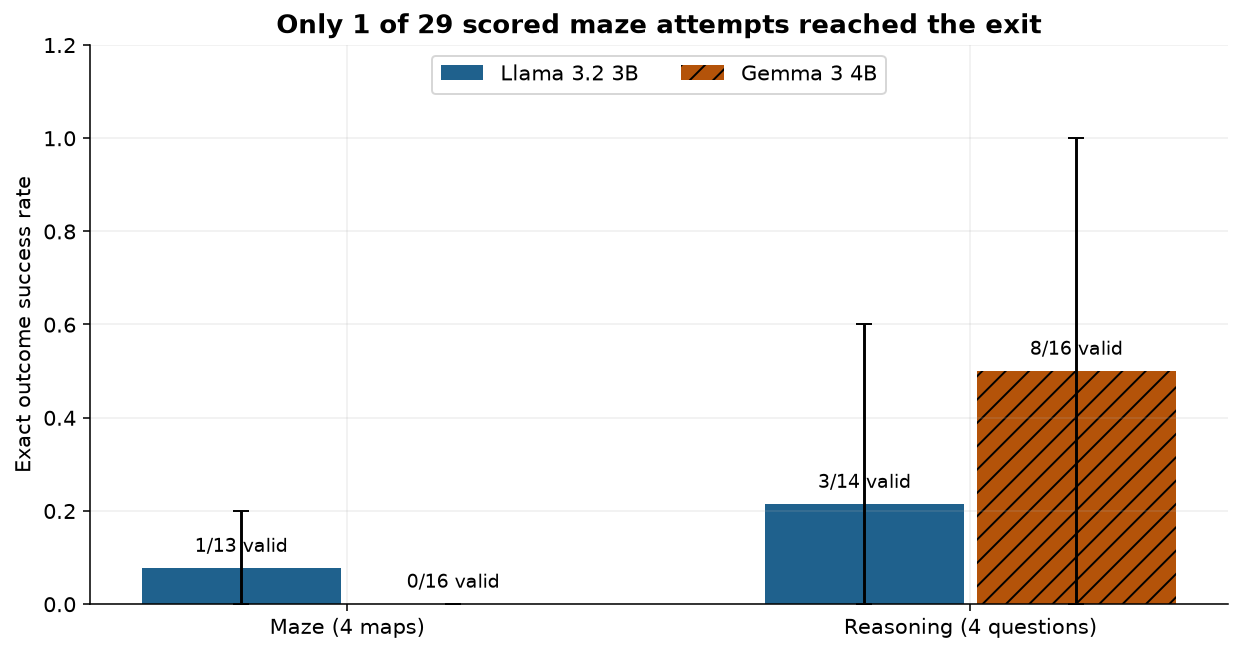

In [8]:
fig, ax = plt.subplots(figsize=(9,4.8))
for index, model in enumerate(MODELS):
    rows = summary[summary.model == model].set_index("family").loc[["maze","reasoning"]]
    positions = np.arange(2) + (index-.5)*.34
    bars = ax.bar(positions, rows.success_rate, .32, label=LABELS[model], color=COLOURS[model],
        hatch="//" if index else "", yerr=np.vstack([rows.success_rate-rows.ci_low,
        rows.ci_high-rows.success_rate]), capsize=4)
    for bar, (_,r) in zip(bars,rows.iterrows()):
        ax.text(bar.get_x()+bar.get_width()/2, min(1.13,bar.get_height()+.035),
                f'{int(r.successes)}/{int(r.valid_outcomes)} valid', ha="center", fontsize=10)
ax.set(xticks=np.arange(2), xticklabels=["Maze (4 maps)","Reasoning (4 questions)"],
    ylabel="Exact outcome success rate", ylim=(0,1.2),
    title="Only 1 of 29 scored maze attempts reached the exit")
ax.legend(loc="upper center", ncols=2)
fig.tight_layout(); fig.savefig(FIGURES / "success_rates.png", bbox_inches="tight"); plt.show()

Mazes were far harder than questions for both models: 1 of 29 scored maze attempts reached the exit (Llama 1 of 13, Gemma 0 of 16), against 11 of 30 question attempts (Llama 3 of 14, Gemma 8 of 16). Gemma's maze result is a floor. Gemma's question interval runs from 0% to 100%, and its maze interval has zero width only because all four maze rates were 0; neither says anything about future attempts. If Llama's 5 first-round attempts without a reply are counted as failures, its rate is 4 of 32 instead of 4 of 27; if they are counted as successes, 9 of 32. Gemma's 8 of 32 lies inside that range, so the two models cannot be ranked overall.

The per-task results come from the outcome lists printed in Section 6 and `data/groups.csv`:

| Task | Llama 3.2 3B, first round | Gemma 3 4B, first round | Second round |
|---|---|---|---|
| `maze-01` | 1 of 4 (0, 0, 1, 0), mixed | 0 of 4 | |
| `maze-02` | 0 of 2, 2 no reply | 0 of 4 | |
| `maze-03` | 0 of 3, 1 no reply | 0 of 4 | |
| `maze-04` | 0 of 4 | 0 of 4 | |
| `reason-01` | 2 of 2, 2 no reply | 4 of 4 | |
| `reason-02` | 0 of 4 | 0 of 4 | Llama 0 of 4 |
| `reason-03` | 1 of 4 (1, 0, 0, 0), mixed | 4 of 4 | Llama 0 of 3, 1 no reply; Gemma 4 of 4 |
| `reason-04` | 0 of 4 | 0 of 4 | Gemma 0 of 4 |

Apart from the 6 attempts that got no reply, every failure was a readable reply that was wrong. The table below sorts all 80 attempts (from `data/episodes.jsonl`, field `stop_reason`).

| Model | Round | Attempts | No reply (HTTP 429) | Unreadable reply | Wrong | Succeeded |
|---|---|---|---|---|---|---|
| Llama 3.2 3B | First | 32 | 5 | 0 | 23 | 4 |
| Llama 3.2 3B | Second | 8 | 1 | 0 | 7 | 0 |
| Gemma 3 4B | First | 32 | 0 | 0 | 24 | 8 |
| Gemma 3 4B | Second | 8 | 0 | 0 | 4 | 4 |
| Total | | 80 | 6 | 0 | 58 | 16 |

All 330 replies that came back ended normally and could be scored. Of the 58 wrong attempts, 28 were mazes that used all ten moves without reaching the exit and 30 were wrong answers to questions. Ten of the wrong arithmetic answers included working despite the instruction to return only the answer, but their final numbers were also wrong, and the environment's partial-credit rule, which rewards a correct answer inside longer text, gave none of the 30 any credit. So no reply was a right answer in the wrong format.

The next chart counts the 13 complete first-round groups by type: all four failed, mixed, or all four succeeded. Blue is Llama (5 complete groups), hatched orange Gemma (8). Only the middle pair matters for training by comparison. The cell also saves the group, success-rate and comparison-score tables to `data/`.

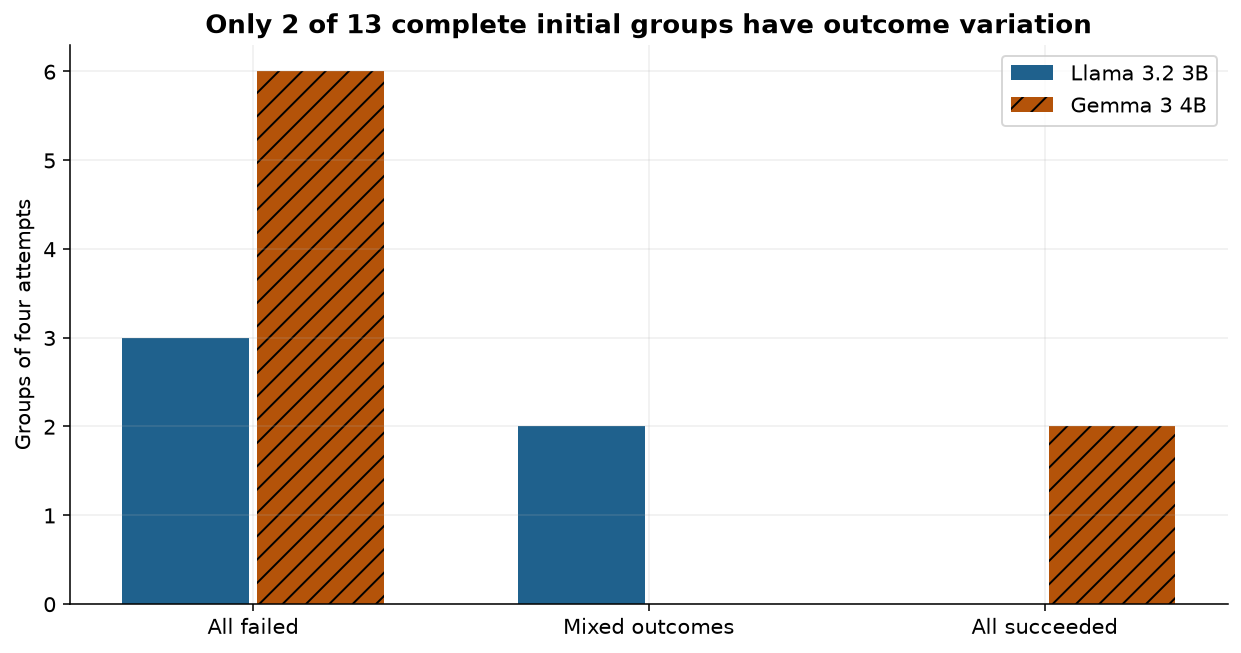

In [9]:
fig, ax = plt.subplots(figsize=(9,4.8))
for i, model in enumerate(MODELS):
    group = gdf[(gdf.phase == "uniform") & (gdf.model == model) & gdf.complete]
    counts = [int(group.all_failed.sum()),int(group.mixed.sum()),int(group.all_success.sum())]
    ax.bar(np.arange(3)+(i-.5)*.34,counts,.32,label=LABELS[model],color=COLOURS[model],hatch="//" if i else "")
ax.set(xticks=np.arange(3),xticklabels=["All failed","Mixed outcomes","All succeeded"],
       ylabel="Groups of four attempts",title="Only 2 of 13 complete initial groups have outcome variation")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.legend(); fig.tight_layout(); fig.savefig(FIGURES / "group_signal.png",bbox_inches="tight"); plt.show()
summary.to_csv(DATA / "results.csv",index=False,lineterminator="\n")
gdf.to_csv(DATA / "groups.csv",index=False,lineterminator="\n")
write_jsonl(DATA / "advantages.jsonl",advantage_rows)

Only 2 of 13 complete groups were mixed, and both were Llama's: `maze-01` and `reason-03`, each with 1 success in 4. Llama had 3 all-failed groups; 3 more of its groups were incomplete. Gemma had 6 all-failed and 2 all-succeeded groups. So 11 of 13 complete groups give every attempt a comparison score of zero, including Gemma's two perfect groups. A model can score better on a task and still give a trainer less to learn from it.

Gemma's lack of mixed groups has a visible cause in its replies. In 7 of its 8 first-round groups, its four attempts were identical: the same ten moves on each maze, the same text on three of the four questions (counted from `data/episodes.jsonl`, comparing each attempt's moves or trimmed reply). Only `reason-02` drew different replies, three distinct wrong numbers. Llama's attempts differed in every maze group; its only exact repeats were the two `-38` answers to `reason-01` and two identical wrong reversals of `reason-03`. With identical attempts, a group of four is one attempt paid for four times. Section 9 shows examples.

The coverage bonus gave scores to 1 of the 5 complete all-failed maze groups, Llama's `maze-04`. Gemma's four all-failed maze groups had identical moves, so their coverage did not differ and the bonus stayed zero. With the bonus, 12 attempts in complete groups have a non-zero score instead of 8 (`data/advantages.jsonl`). Section 9 shows that the extra scores reward the wrong attempts.

## 8. Stopping early and choosing second-round tasks

The code below replays the early-stop rule on each first-round group, in the order the attempts were collected, and records where it would have stopped and why (`data/sara_decisions.jsonl`). It counts the calls of the attempts the rule would have used against the calls of all four, and checks against the full group whether a mixed group would have been missed. Groups with a provider error are recorded but left out of the totals, because stopping after an error would otherwise count as a saving.

The table printed first sums the 13 complete groups per model: attempts the rule would have used (`consumed_episodes`), calls with the rule (`prefix_calls`) and with all four attempts (`full_calls`), mixed groups kept (`mixed_committed`) and mixed groups missed. In the chart, the left pair of bars is the calls actually made on the 13 complete groups, per model; the right pair is the calls the rule would have made on the same groups. The right-hand calls are a subset of the left-hand ones, not a separate collection: every call was made and paid for. The chart's labels use the code name SARA for the early-stop rule and "counterfactual" for the replay.

,consumed_episodes,prefix_calls,full_calls,mixed_committed,missed_mixed
model,,,,,
google/gemma-3-4b-it,24,132,176,0,0
meta-llama/llama-3.2-3b-instruct,14,61,85,2,0


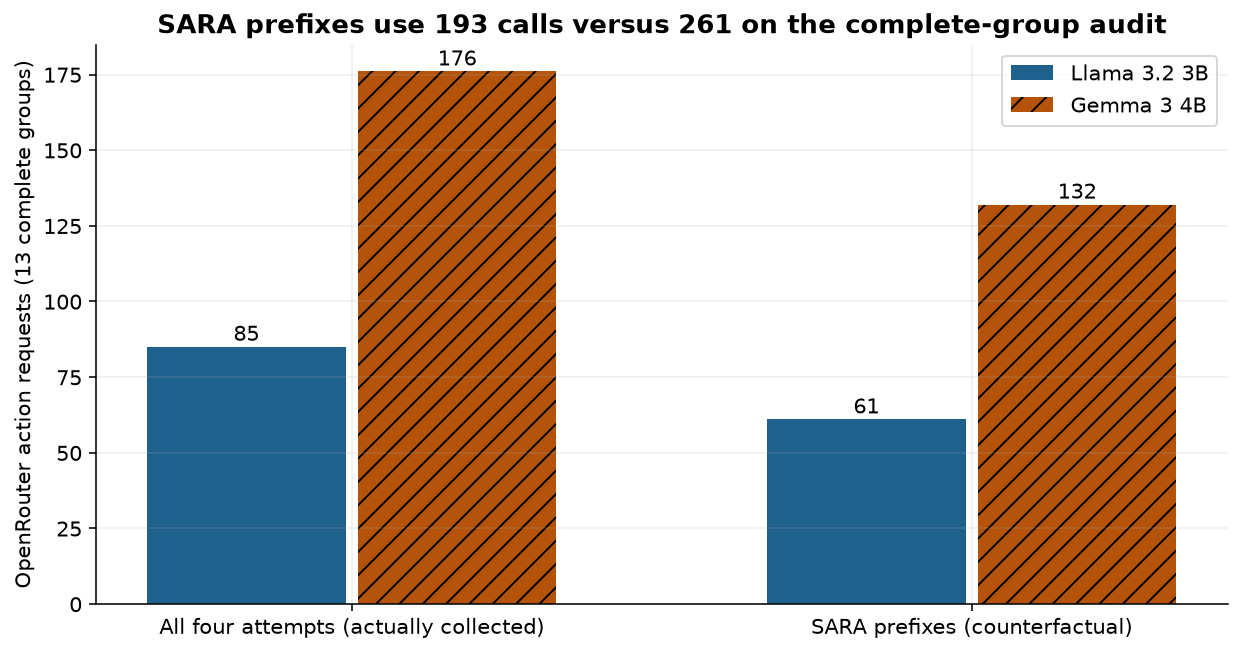

In [10]:
sara_rows = []
for model in MODELS:
    for task in TASKS:
        group = sorted([e for e in EPISODES if e["phase"]=="uniform" and
                        e["model"]==model and e["task_id"]==task["id"]],key=lambda e:e["replicate"])
        result = sara_prefix(group)
        full_complete = all(e["data_valid"] and e["stop_reason"]!="output_length" for e in group)
        actual_mixed = (0 < sum(e["outcome_reward"] for e in group) < 4) if full_complete else None
        used = result["used"]
        sara_rows.append({"model":model,"task_id":task["id"],**result,"full_complete":full_complete,
            "full_group_mixed":actual_mixed,"missed_mixed":bool(actual_mixed and result["decision"]!="commit") if full_complete else None,
            "full_calls":sum(e["model_calls"] for e in group),
            "prefix_calls":sum(e["model_calls"] for e in group[:used]),
            "audit_only_calls":sum(e["model_calls"] for e in group[used:])})
write_jsonl(DATA / "sara_decisions.jsonl",sara_rows)
sd = pd.DataFrame(sara_rows)
display(sd[sd.full_complete].drop(columns=["history"]).groupby("model").agg(
    consumed_episodes=("used","sum"),prefix_calls=("prefix_calls","sum"),
    full_calls=("full_calls","sum"),mixed_committed=("decision",lambda s:int((s=="commit").sum())),
    missed_mixed=("missed_mixed","sum")))
fig, ax = plt.subplots(figsize=(9,4.8))
for i, model in enumerate(MODELS):
    rows = sd[(sd.model==model) & sd.full_complete]
    values = [int(rows.full_calls.sum()),int(rows.prefix_calls.sum())]
    bars = ax.bar(np.arange(2)+(i-.5)*.34, values,.32,label=LABELS[model],color=COLOURS[model],hatch="//" if i else "")
    for b,v in zip(bars,values): ax.text(b.get_x()+b.get_width()/2,b.get_height()+2,str(v),ha="center")
ax.set(xticks=np.arange(2),xticklabels=["All four attempts (actually collected)","SARA prefixes (counterfactual)"],
       ylabel="OpenRouter action requests (13 complete groups)",title="SARA prefixes use 193 calls versus 261 on the complete-group audit")
ax.legend(); fig.tight_layout(); fig.savefig(FIGURES / "sara_cost.png",bbox_inches="tight"); plt.show()

| Model | Complete groups | Attempts, all four | Attempts, early stop | Calls, all four | Calls, early stop | Mixed groups kept |
|---|---|---|---|---|---|---|
| Llama 3.2 3B | 5 | 20 | 14 | 85 | 61 | 2 of 2 |
| Gemma 3 4B | 8 | 32 | 24 | 176 | 132 | 0 of 0 |

The rule would have used 38 of 52 attempts and 193 of 261 calls, 68 fewer (26.1%), and it kept both mixed groups. It gave up on all 11 groups whose first three outcomes agreed, and stopped the two mixed groups as soon as they mixed. Of the 68 calls it would have skipped, 56 were fourth attempts at tasks whose first three agreed and 12 were attempts after a group had already mixed; 60 of the 68 were maze calls, because a maze attempt costs up to ten times as much as a question (counted from `data/sara_decisions.jsonl`, field `audit_only_calls`).

No mixed group was lost, but the only mixed maze group survived by one attempt (Section 5). Gemma's `maze-01` group shows the ordinary case: three failures, the chance of a mix fell to 0.2, and the rule would have stopped at 30 calls instead of 40; the fourth attempt was the same ten moves again. And the calls saved were not spent on new tasks, so the replay cannot say whether moving them would have found more mixed groups.

The next cell shows the score-guided choice as it was made, before the second round. The table lists each eligible task with its first-round successes, estimated success rate, the variance of that estimate, average calls per attempt, its share of the total score and whether it was chosen. In the chart, each pair of bars is one task. The height is the task's chance of being drawn as the first of the two picks (the axis calls this the "normalized RIDGE sampling score"). Stars mark the tasks actually chosen; an x marks a Llama task that was not eligible because a provider error left its first-round group incomplete. The dashed line at 1/8 is the chance with equal draws over eight tasks. It fits Gemma, but Llama had only 5 eligible tasks, so its equal-draw chance would be 1/5.

,model,task_id,successes,posterior_mean,posterior_variance,cost,normalized_score,selected
0,meta-llama/llama-3.2-3b-instruct,maze-01,1,0.3,0.035,8.25,0.0577,False
1,meta-llama/llama-3.2-3b-instruct,maze-04,0,0.1,0.015,10.00,0.0222,False
2,meta-llama/llama-3.2-3b-instruct,reason-02,0,0.1,0.015,1.00,0.2221,True
3,meta-llama/llama-3.2-3b-instruct,reason-03,1,0.3,0.035,1.00,0.4758,True
4,meta-llama/llama-3.2-3b-instruct,reason-04,0,0.1,0.015,1.00,0.2221,False
5,google/gemma-3-4b-it,maze-01,0,0.1,0.015,10.00,0.0227,False
6,google/gemma-3-4b-it,maze-02,0,0.1,0.015,10.00,0.0227,False
7,google/gemma-3-4b-it,maze-03,0,0.1,0.015,10.00,0.0227,False
8,google/gemma-3-4b-it,maze-04,0,0.1,0.015,10.00,0.0227,False
9,google/gemma-3-4b-it,reason-01,4,0.9,0.015,1.00,0.2273,False


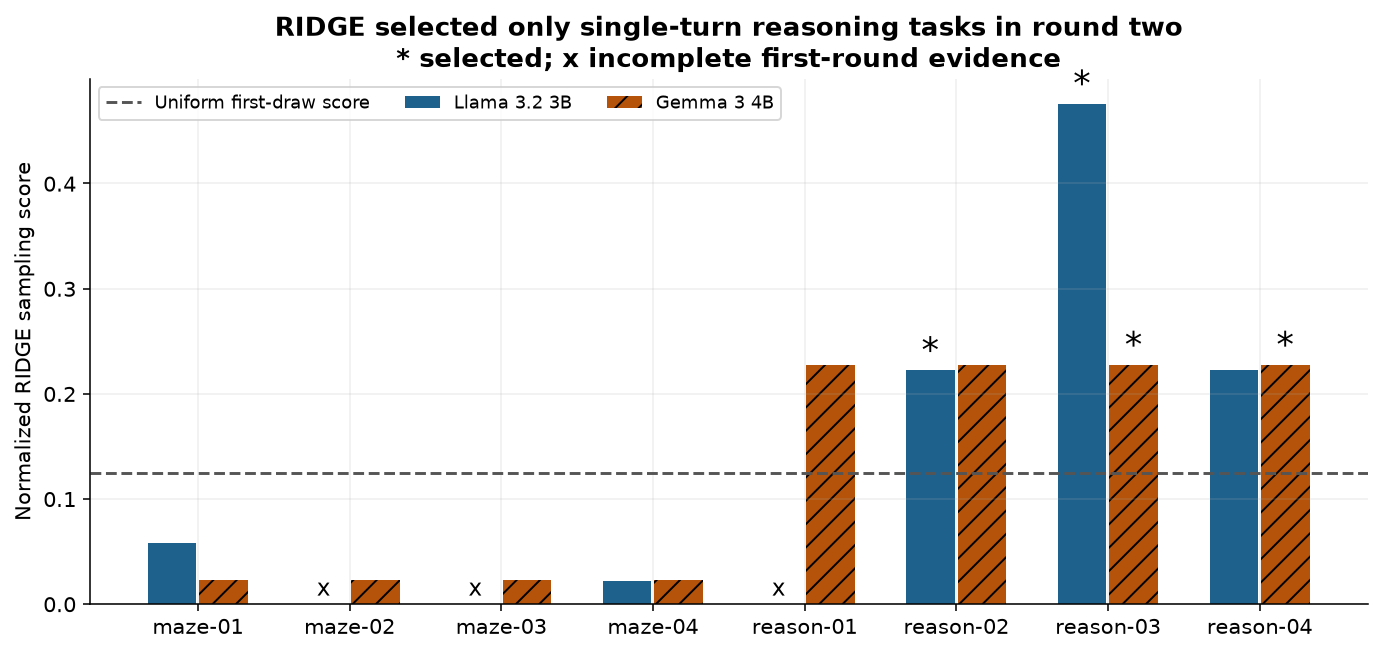

In [11]:
plan_rows = [{"model":model,**row,"selected":row["task_id"] in plan["selected"]}
             for model,plan in PLANS.items() for row in plan["selection_rows"]]
plan_df = pd.DataFrame(plan_rows)
display(plan_df[["model","task_id","successes","posterior_mean","posterior_variance",
                 "cost","normalized_score","selected"]].round(4))
fig, ax = plt.subplots(figsize=(10,4.8))
for i,model in enumerate(MODELS):
    rows = plan_df[plan_df.model==model].set_index("task_id").reindex([t["id"] for t in TASKS])
    bars=ax.bar(np.arange(len(TASKS))+(i-.5)*.34,rows.normalized_score.fillna(0),.32,
                label=LABELS[model],color=COLOURS[model],hatch="//" if i else "")
    for b,selected in zip(bars,rows.selected):
        if pd.isna(selected): ax.text(b.get_x()+b.get_width()/2,.008,"x",ha="center",fontsize=12)
        elif selected: ax.text(b.get_x()+b.get_width()/2,b.get_height()+.008,"*",ha="center",fontsize=18)
ax.axhline(1/len(TASKS),color="#555555",ls="--",label="Uniform first-draw score")
ax.set(xticks=np.arange(len(TASKS)),xticklabels=[t["id"] for t in TASKS],
       ylabel="Normalized RIDGE sampling score",title="RIDGE selected only single-turn reasoning tasks in round two\n* selected; x incomplete first-round evidence")
ax.legend(ncols=3,fontsize=9); fig.tight_layout(); fig.savefig(FIGURES / "ridge_selection.png",bbox_inches="tight"); plt.show()
plan_df.to_csv(DATA / "ridge_selection.csv",index=False,lineterminator="\n")

| Model | Chosen task | First-round result | Estimated success rate | Calls per attempt | Chance of being drawn first |
|---|---|---|---|---|---|
| Llama 3.2 3B | `reason-02` | 0 of 4 | 0.10 | 1.00 | 22.2% |
| Llama 3.2 3B | `reason-03` | 1 of 4 | 0.30 | 1.00 | 47.6% |
| Gemma 3 4B | `reason-03` | 4 of 4 | 0.90 | 1.00 | 22.7% |
| Gemma 3 4B | `reason-04` | 0 of 4 | 0.10 | 1.00 | 22.7% |

The choice went only to questions. The cost division decided it: Llama's two mixed groups had the same estimate, 0.3, but `maze-01` got 5.8% because its attempts cost 8.25 calls, while `reason-03` got 47.6%. For Gemma the score could not tell its four questions apart. With no mixed group, its target sat at 0.5, and its estimates of 0.1 and 0.9 lie at equal distances from it, so all four questions scored 22.7% and the pick was a random draw among them (`data/ridge_selection.csv`).

The second round produced no mixed group. Gemma repeated its first-round results exactly: 4 of 4 on `reason-03`, 0 of 4 on `reason-04`. Llama failed all 4 attempts at `reason-02` and 3 attempts at `reason-03`, where its fourth got no reply, so that group is incomplete; it had solved `reason-03` once in the first round. Of the 15 second-round attempts with an outcome, 4 succeeded, all Gemma's. Because no new group was mixed, neither model's target moved (Llama stayed at 0.30 with tolerance 0.05, Gemma at 0.5 and 0.15). With two picks per model and Gemma's ties, this round is too small to say whether score-guided choice beats equal draws.

## 9. Worked examples and error analysis

The code below picks examples by a fixed rule: the first maze success, the first maze failure, the first question success and the first question failure in the first round, plus the attempts with the lowest and highest coverage in the all-failed maze group whose coverage varies most. It saves their identifiers to `data/case_ids.json` and draws the maze attempts on their maps. The text after the figures adds examples from the groups that explain the results above.

Each panel is one Llama attempt drawn on its map: black squares are walls, S the start, E the exit, and the line the path. The small numbers give the move after which the model was on that square, with 0 for the start; "0..10" means it was there from the start through move 10, because every move hit a wall. The panel title gives the outcome and why the attempt ended ("horizon" means it used all ten moves). Top left is the successful attempt from Section 5; top right is `uniform-maze-01-meta-llama-0`; the bottom row is `uniform-maze-04-meta-llama-0` and `-1`.

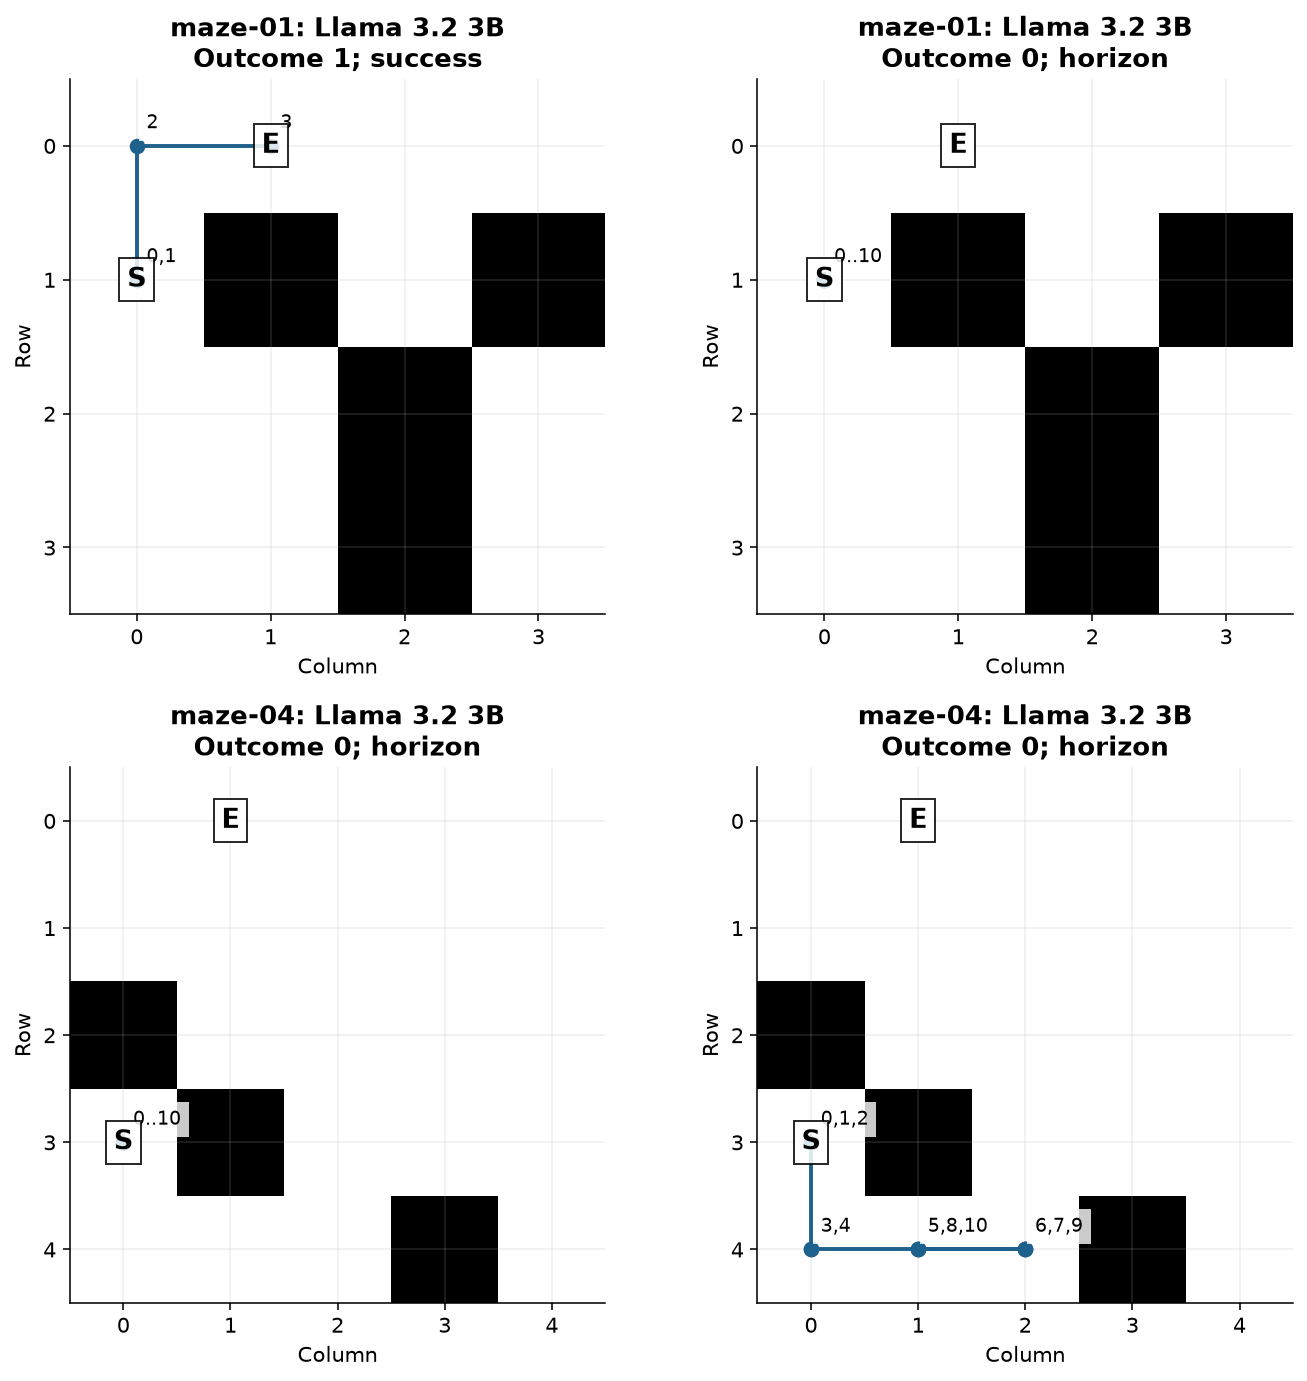

In [12]:
by_task = {t["id"]:t for t in TASKS}
case_ids = []
for family, success in [("maze",1),("maze",0),("reasoning",1),("reasoning",0)]:
    candidates = [e for e in EPISODES if e["phase"]=="uniform" and e["family"]==family
                  and e["data_valid"] and e["outcome_reward"]==success]
    if candidates:
        case_ids.append(candidates[0]["episode_id"])
    else:
        print(f"No measured {family} case with outcome {success} in the initial sample.")
failed_groups = gdf[(gdf.phase=="uniform") & (gdf.family=="maze") & gdf.complete & gdf.all_failed]
if not failed_groups.empty:
    hardest = failed_groups.sort_values("coverage_std",ascending=False).iloc[0]
    candidates = [e for e in EPISODES if e["phase"]=="uniform" and
                  e["task_id"]==hardest.task_id and e["model"]==hardest.model]
    case_ids.extend([min(candidates,key=lambda e:e["coverage_rate"])["episode_id"],
                     max(candidates,key=lambda e:e["coverage_rate"])["episode_id"]])
case_ids = list(dict.fromkeys(case_ids))
for e in EPISODES:
    if len(case_ids)>=5: break
    if e["episode_id"] not in case_ids and e["phase"]=="uniform": case_ids.append(e["episode_id"])
save_json(DATA / "case_ids.json",case_ids)
cases = [next(e for e in EPISODES if e["episode_id"]==key) for key in case_ids]
maze_cases = [e for e in cases if e["family"]=="maze"]
panel_rows = math.ceil(len(maze_cases)/2)
fig, axes = plt.subplots(panel_rows,2,figsize=(10,5*panel_rows),squeeze=False)
for ax in axes.flat: ax.set_axis_off()
for ax,e in zip(axes.flat,maze_cases):
    ax.set_axis_on()
    task=by_task[e["task_id"]]
    ax.imshow(task["board"],cmap="Greys",vmin=0,vmax=1,origin="upper")
    path=[task["start"]]+[t["next_observation"]["current_position"] for t in e["transitions"] if t["next_observation"]]
    xs,ys=zip(*path); ax.plot(xs,ys,"o-",color=COLOURS[e["model"]],linewidth=2,markersize=7)
    visits = {}
    for index,point in enumerate(path): visits.setdefault(tuple(point),[]).append(index)
    for (x,y),indices in visits.items():
        label = ",".join(map(str,indices)) if len(indices)<=4 else f"{indices[0]}..{indices[-1]}"
        ax.annotate(label,(x,y),xytext=(5,9),textcoords="offset points",fontsize=10,
                    bbox={"facecolor":"white","edgecolor":"none","alpha":.8})
    for point,label in [(task["start"],"S"),(task["goal"],"E")]:
        ax.text(point[0],point[1],label,ha="center",va="center",fontweight="bold",fontsize=14,
                bbox={"facecolor":"white","edgecolor":"black","alpha":.85})
    ax.set(title=f'{task["id"]}: {LABELS[e["model"]]}\nOutcome {e["outcome_reward"]}; {e["stop_reason"]}',
           xlabel="Column",ylabel="Row",xticks=range(len(task["board"][0])),yticks=range(len(task["board"])))
fig.tight_layout(); fig.savefig(FIGURES/"maze_cases.png",bbox_inches="tight"); plt.show()

### Walking into the same wall

`uniform-maze-01-meta-llama-0` replied `{"action": 3}` (right) ten times. The square to the right of the start is a wall, so the model never moved, collected ten penalties of -0.75 (-7.50) and outcome 0. This was common for Llama: 72 of its 125 first-round maze moves (57.6%) were into a wall or off the edge, and 79 of the 125 (63%) asked for "right". The prompt's only example is `{"action": 3}`, which may pull the model towards "right", but no prompt without that example was tried, so the cause is open.

### Legal moves that go nowhere

Gemma made no illegal moves in 160 first-round maze moves and still reached no exit. On `maze-01`, all four of its attempts (`uniform-maze-01-google-0` to `-3`) made the same ten moves: down to `[0,2]`, then right and left between `[0,2]` and `[1,2]` until the moves ran out. The exit is up from the start. Its other three mazes show the same pattern of four identical attempts. The requests asked for temperature 0.9 and used a different seed for each attempt; the saved responses record nothing that shows why the replies were identical, so it is not known whether the model or the provider's sampling produced the repeats.

### When the step rewards mislead

Gemma's maze attempts average -1.95 in step rewards and Llama's -3.79 (`data/results.csv`, `mean_native_return`), so by step rewards Gemma did better. That comes from avoiding walls, not from progress: Gemma's back-and-forth costs 0.25 a move, Llama's wall bumps 0.75, and only Llama ever reached an exit. A collection judged by its step-reward totals would have preferred the model that never solved a maze, which is why the outcome decides success here.

The coverage bonus misleads in a similar way. In Llama's all-failed `maze-04` group, attempt `uniform-maze-04-meta-llama-0` never left the start, while `uniform-maze-04-meta-llama-1` moved down and along the bottom row, reaching three new squares. The exit is at `[1,0]`, at the top, so the second attempt went the wrong way.

The next chart shows that group. The upper panel gives each of the four attempts' share of moves that reached a new square. The lower panel gives the comparison scores: black dots are the outcome-based scores, all zero, and orange bars the coverage-bonus scores.

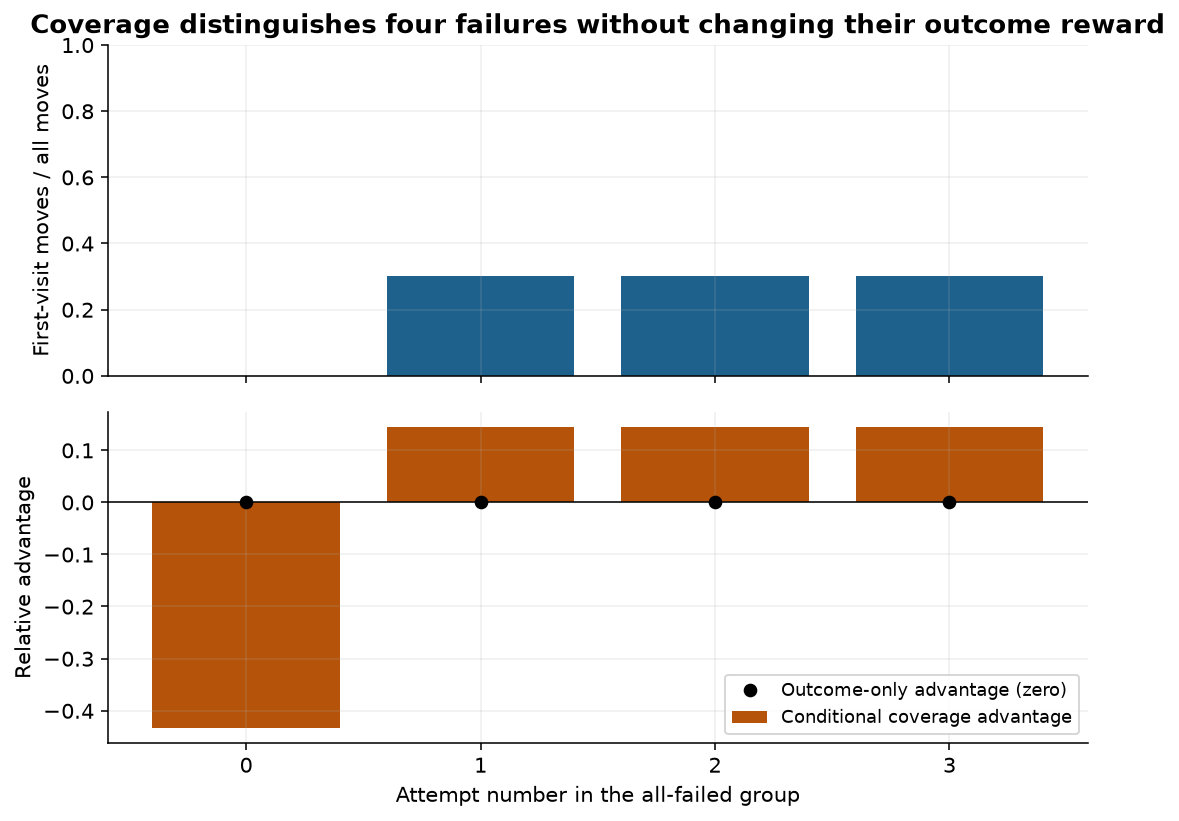

In [13]:
if not failed_groups.empty:
    group_cases = sorted(candidates,key=lambda e:e["replicate"])
    _,base,cov,fallback = group_advantages(group_cases)
    fig,axes = plt.subplots(2,1,figsize=(8,6),sharex=True)
    axes[0].bar(range(4),[e["coverage_rate"] for e in group_cases],color="#1f618d")
    axes[0].set(ylabel="First-visit moves / all moves",ylim=(0,1),
                title="Coverage distinguishes four failures without changing their outcome reward")
    axes[1].bar(range(4),cov,color="#b45309",label="Conditional coverage advantage")
    axes[1].plot(range(4),base,"ko",label="Outcome-only advantage (zero)")
    axes[1].axhline(0,color="black",lw=.8)
    axes[1].set(ylabel="Relative advantage",xlabel="Attempt number in the all-failed group",
                xticks=range(4),xticklabels=["0","1","2","3"])
    axes[1].legend(fontsize=9)
    fig.tight_layout(); fig.savefig(FIGURES/"coverage_signal.png",bbox_inches="tight"); plt.show()

The coverage shares are 0, 0.3, 0.3 and 0.3, and the coverage-bonus scores are -0.43 for the attempt that stayed put and +0.14 for each of the three that moved. The bonus would tell a trainer to prefer moving along the bottom row, away from the exit. Moving at all may still be better than ten wall bumps, but these four attempts cannot show that it leads towards the exit.

### A typical success

`uniform-reason-01-meta-llama-0` received `Calculate 2 - 40.` and returned `-38`: step reward 1, outcome 1. Gemma answered `-38` in all four attempts, so its group's comparison scores are all zero.

### Arithmetic that goes wrong early

`reason-02` asks for `( 551 * -29 ) + ( -355 * 717 - 71 ) * 164`, whose value is -41771363: 551 x -29 = -15979, -355 x 717 - 71 = -254606, and -15979 + (-254606 x 164) = -41771363. Every attempt by both models failed, in both rounds. `uniform-reason-02-meta-llama-0` returned `-66621503`. Gemma wrote out its working, against the instruction; in `uniform-reason-02-google-0` the first line is `-15995 + (-253735 - 71) * 164`, so the first product is already off by 16, and the final line is `-41753579`. A looser reader that took the last number would not have changed any of these scores.

### One task, two models, opposite usefulness

`reason-03` asks for the reverse of `it, in, say, the, stress, copies`. Gemma returned the exact answer, `copies, stress, the, say, in, it`, in all four first-round attempts and all four second-round attempts. Llama returned it once (`uniform-reason-03-meta-llama-0`); attempts 1 and 2 both returned `say, the, stress, copies, in, it`, which keeps the words but not the order. Gemma is the better model on this task and gives a trainer nothing; Llama's single success among three failures is one of the two useful groups in the study. In the second round, Llama's three answered attempts all failed, one of them `say the stress copies in it` without commas, so the contrast did not repeat.

### A near miss repeated eight times

`reason-04` asks to reverse a 20-word list. Gemma returned the same 19-word reply in all eight attempts across both rounds: it drops the first word, `bore`, and swaps `BUT` and `the`. Llama's four first-round replies were all different and all wrong: each drops or reorders several words, and one adds the word `second`, which is not in the list. For Gemma, the second round bought four more copies of an answer already seen four times.

### Lost attempts

All 6 provider errors were HTTP 429 replies ("temporarily rate-limited upstream") from Parasail serving Llama, between 09:24 and 09:26, and none was retried. In two of the lost groups the errors came late: `reason-01` had 2 successes before them, and `maze-03` had 3 failures, enough for the early-stop rule to give up before the fourth attempt's error.

These examples show what the models returned, not why. The pattern they share is that the groups with no contrast came from two sources: tasks the model could not do (most mazes, `reason-02`, `reason-04`) and, for Gemma, attempts that repeated each other exactly.

## 10. Saved records and spend

The code below writes every attempt to `data/rollouts_for_training_demo.jsonl`, joined with its comparison scores, and one row per move to `data/steps.jsonl`. It then audits the collection. For every maze move it recomputes the new position and the step reward from the rules in Section 4 and checks them against what the environment returned; for every question it recomputes the step reward from the answer. It checks that every cache file's name matches a hash of its full request and that every cached response is used by exactly one move, so no two attempts share a response. Finally it totals spend and tokens and writes package versions, file hashes and counts to `data/manifest.json`.

The saved records are not ready-made training data. A trainer that updates a model needs attempts produced by that exact model, with its tokens and their probabilities. The records hold the messages, moves, step rewards, outcomes and scores, but no token IDs, no confirmed weight version and, for Gemma, no token probabilities, so every record is marked `exact_on_policy_ready=false`.

In [14]:
adv_by_id = {r["episode_id"]:r for r in advantage_rows}
export, steps = [], []
for e in EPISODES:
    advantages = adv_by_id.get(e["episode_id"])
    row = {**e, "advantages":advantages, "schema_version":PROTOCOL,
        "exact_on_policy_ready":False, "token_ids":None, "token_loss_mask":None,
        "behavior_weight_revision":None, "tokenizer_revision":None,
        "training_candidate":bool(e["data_valid"] and e["stop_reason"] != "output_length" and advantages),
        "outcome_contract":"binary exact answer or exit reached within horizon",
        "coverage_contract":"first-visit position rate, auxiliary only"}
    export.append(row)
    for t in e["transitions"]:
        steps.append({"episode_id":e["episode_id"],"t":t["t"],"request_key":t["request_key"],
            "assistant_message":t["assistant_text"],"assistant_role_mask":int(t["assistant_text"] is not None),
            "observation":t["observation"],"action":t["action"],"next_observation":t["next_observation"],
            "environment_role_mask":0,"native_reward":t["native_reward"],
            "outcome_reward":t["outcome_reward"],"first_visit":t["first_visit"],
            "advantage_if_used": advantages["covgpo_advantage"] if advantages else None,
            "terminated":e["terminated"] and t is e["transitions"][-1],
            "truncated":e["truncated"] and t is e["transitions"][-1]})
write_jsonl(DATA/"rollouts_for_training_demo.jsonl",export)
write_jsonl(DATA/"steps.jsonl",steps)

cached = {p.stem:json.loads(p.read_text(encoding="utf-8")) for p in CACHE.glob("*.json")}
pilot_cached = {p.stem:json.loads(p.read_text(encoding="utf-8")) for p in (DATA/"pilot_cache").glob("*.json")}
checks = Counter()
for e in EPISODES:
    assert all(k in cached for k in e["response_cache_keys"])
    assert math.isclose(e["native_return"],sum(t["native_reward"] or 0 for t in e["transitions"]),abs_tol=1e-9)
    assert not (e["terminated"] and e["truncated"])
    if e["family"]=="maze":
        native_visited = set()
        for t in e["transitions"]:
            if t["action"] is None: continue
            p=t["observation"]["current_position"]; q=t["next_observation"]["current_position"]
            task=by_task[e["task_id"]]; a=t["action"]["action"]
            dx,dy=DIRECTIONS[a]; proposed=[p[0]+dx,p[1]+dy]
            legal=a in t["observation"]["legal_actions"]
            assert q == (proposed if legal else p)
            assert task["board"][q[1]][q[0]] == 0
            expected_reward = (-.75 if not legal else 10.0 if q==task["goal"] else
                               -.25 if tuple(q) in native_visited else -.05)
            assert math.isclose(t["native_reward"],expected_reward,abs_tol=1e-9)
            if legal: native_visited.add(tuple(q))
    else:
        task=by_task[e["task_id"]]
        for t in e["transitions"]:
            if t["action"] is None: continue
            answer=t["action"]["answer"]
            expected_reward=(1.0 if answer==task["answer"] else
                             len(task["answer"])/len(answer) if answer and task["answer"] in answer else 0.0)
            assert math.isclose(t["native_reward"],expected_reward,abs_tol=1e-9)
    checks["episode_reward_and_transition_audit"] += 1
for key,row in cached.items(): assert digest(row["request"]) == key == row["cache_key"]
references = [k for e in EPISODES for k in e["response_cache_keys"]]
assert set(references) == set(cached), "Every measured request is accounted for."
assert max(Counter(references).values()) == 1, "Distinct attempts must not reuse one sampled response."
assert len(set(e["episode_id"] for e in EPISODES)) == len(EPISODES)
assert all(not e["exact_on_policy_ready"] for e in export)
billed = {**pilot_cached, **cached}
billing = {"requests":len(cached),"setup_probe_requests":len(pilot_cached),
    "reported_cost_usd":sum(r["accounted_cost_usd"] for r in billed.values()
    if r["cost_basis"]=="provider reported usage.cost"),
    "conservative_unreported_bound_usd":sum(r["accounted_cost_usd"] for r in billed.values()
    if r["cost_basis"]!="provider reported usage.cost"),
    "prompt_tokens":sum(r["response"].get("usage",{}).get("prompt_tokens",0) for r in billed.values()),
    "completion_tokens":sum(r["response"].get("usage",{}).get("completion_tokens",0) for r in billed.values()),
    "failed_requests":sum(not r["ok"] for r in billed.values()),
    "total_request_latency_s":sum(r["latency_s"] for r in billed.values()),
    "model_updates":0}
manifest={"protocol":PROTOCOL,"environment_revision":OPENENV_REVISION,
    "python":platform.python_version(),"platform":platform.platform(),
    "packages":{p:metadata.version(p) for p in ["openenv","openenv-maze-env",
        "openenv-reasoning-gym","reasoning-gym","numpy","pandas","matplotlib","requests","uvicorn","websockets"]},
    "config":{k:globals()[k] for k in ["MODELS","N_MAZES","N_REASONING","N_ROLLOUTS","N_RIDGE_TASKS",
        "MAX_STEPS","MAX_EPISODES","MAX_REQUESTS","MAX_SPEND_USD","TEMPERATURE",
        "SARA_PROBE","SARA_ABANDON","COVERAGE_SCALE","COVERAGE_MIN_STD"]},
    "counts":{"tasks":len(TASKS),"episodes":len(EPISODES),"groups":len(groups),"environment_steps":sum(e["environment_steps"] for e in EPISODES)},
    "audits":dict(checks),"billing":billing,
    "file_hashes":{p.relative_to(DATA).as_posix():hashlib.sha256(p.read_bytes()).hexdigest()
        for p in sorted(DATA.rglob("*")) if p.is_file() and "tmp" not in p.parts and p.name!="manifest.json"}}
save_json(DATA/"manifest.json",manifest)
display(pd.DataFrame([billing]))
print("Verified",dict(checks),"and",len(cached),"full-request hashes.")
print(f"Spend: ${billing['reported_cost_usd']:.6f} provider-reported; "
      f"unreported upper bound ${billing['conservative_unreported_bound_usd']:.6f}. Weight updates: 0.")

,requests,setup_probe_requests,reported_cost_usd,conservative_unreported_bound_usd,prompt_tokens,completion_tokens,failed_requests,total_request_latency_s,model_updates
0,336,2,0.015311,0.001867,294780,3034,7,234.083226,0


Verified {'episode_reward_and_transition_audit': 80} and 336 full-request hashes.
Spend: $0.015311 provider-reported; unreported upper bound $0.001867. Weight updates: 0.


All 80 attempts passed the reward and move audit, and all 336 cache files match their requests.

| Saved record | Count |
|---|---|
| Fresh tasks | 8 |
| Attempts | 80 |
| Attempts with a scored outcome | 74 |
| Attempts with no reply (provider error) | 6 |
| Moves and answers applied by the environments | 330 |
| Complete groups, both rounds | 16 |
| Attempts with a comparison score (in complete groups) | 64 |
| Attempts with a non-zero comparison score | 8 |
| The same, with the coverage bonus | 12 |
| Records ready for training the exact served model | 0 |
| Model weight updates | 0 |

The other 10 scored attempts belong to incomplete groups and have no comparison score. All 80 records are kept, failures and provider errors included, so a later reader can see what was left out and why.

The spend table above gives 336 measured requests and 2 setup requests. OpenRouter reported $0.0153 for the requests that returned a cost; the 7 failed requests (6 measured, 1 setup, all HTTP 429) reported none, and the conservative bound reserved for them is $0.0019, so the total is under $0.018. The token counts include the setup requests. The latency is a sum of request times (234 seconds), not a benchmark.

## 11. What the evidence supports

- Before collecting at scale, measure a small model's success rate per task, and drop or replace tasks it never solves. Here 288 of the 336 calls went to mazes and bought 1 success; the useful groups came from tasks solved once in four.
- Check that repeated attempts actually differ. Counting distinct replies per group is cheap, and it would have shown at once that Gemma's four attempts were one attempt repeated, which no stopping or choosing rule can fix.
- Skipping the fourth attempt when the first three agree is a safe, small saving on tasks like these: 26% fewer calls with no mixed group lost. With only one mixed maze group, and that one kept by a single attempt, the risk of losing late successes is not measured.
- Do not judge collection by step-reward totals or the coverage bonus alone. Here both favoured attempts that made no progress towards the exit.
- Score-guided choice found no new mixed groups, and for Gemma it reduced to a random draw among tied tasks. Whether it beats equal draws needs a larger task pool.

The uncertainty that most needs another experiment is whether the early-stop rule still keeps its mixed groups, and finds new ones, when the calls it saves are actually spent on fresh tasks of graded difficulty.

## 12. Limitations

Eight tasks, two models and one setting per model (one provider, temperature 0.9) make every count here an illustration rather than a rate. The tasks are freshly generated, but their types are old, and a model can know how to reverse a list without having seen this list.

The early-stop result is a replay on attempts collected in full and in a fixed order. A different order of the same attempts can change its decisions, and the replay does not test spending the saved calls on new tasks, which is how the rule is meant to be used.

Provider errors removed 3 of Llama's 8 first-round groups, and there is no reason to assume the lost attempts would have matched the rest. The ten-move limit is part of the task: a maze attempt that ran out of moves might have succeeded with more. The prompt's example move, `{"action": 3}`, was added after the setup request and may have shaped Llama's choices.

Both models were released in 2024 and 2025, and the notebook does not record why they were chosen over newer small models. Neither hosted provider confirms which weights, tokenizer or chat template it served, and the dated model version was not recorded. The saved attempts are not ready-made training data (Section 10); a later training run should collect again from the model it trains.

The notebook describes the early-stop threshold of 0.30 as set before collection, and the saved cache holds a single collection run; there is no separate preregistration file. The two design changes (Section 6) came before any measured attempt. Details are in `data/PROTOCOL.md`.

## 13. How to reproduce

Running the notebook replays everything from the cache with no network calls; the environments run again on the local machine. Install the pinned packages in a separate virtual environment and run from this folder:

```bash
python -m pip install -r requirements.txt
python -m ipykernel install --user --name openenv-rewards
python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=openenv-rewards 24_openenv_rewards.ipynb
```

A missing cache entry stops the run before any paid request. New collection needs `NB_LIVE=1` and an `OPENROUTER_API_KEY`, in a separate copy with empty `data/cache/` and `data/pilot_cache/` folders; the size settings and caps are in Section 1. To draw new tasks, remove the copy's `data/tasks.json` and change the generator seeds.

| File in `data/` | What it holds |
|---|---|
| `tasks.json` | The 8 frozen tasks with answers, seeds, creation time and hashes |
| `cache/` | One JSON file per model call: full request, full response, cost, time |
| `pilot_cache/` | The 2 setup requests |
| `episodes.jsonl`, `steps.jsonl` | All 80 attempts with every move, reply, step reward and outcome, and one row per move (the files call an attempt an episode; `uniform` is the first round, `ridge` the second) |
| `groups.csv`, `results.csv`, `advantages.jsonl` | Group types, success rates, comparison scores |
| `sara_decisions.jsonl`, `ridge_selection.csv`, `ridge_plans.json` | Early-stop decisions and score-guided choices |
| `rollouts_for_training_demo.jsonl` | All 80 attempts joined with their scores, in a training-style layout |
| `provenance.json`, `model_catalogue.json`, `endpoints_*.json`, `hub_catalogue.json`, `manifest.json`, `validation.json` | Model dates, licences, provider and Hub snapshots, package versions, file hashes, counts, spend and checks |
| `PROTOCOL.md` | Run history |

## 14. Future work and further reading

### Future work

- Enlarge the task pool from 8 to at least 100 tasks of graded difficulty, with several seeds, and measure mixed groups per dollar. The present pool gave 2 mixed groups, too few to compare plans.
- Run the early-stop rule live, spending each skipped fourth attempt on a new task at the same total budget, and count mixed groups found and lost. Here the 68 skipped calls were only marked, not moved.
- Measure attempt diversity directly: repeat Gemma's groups at several temperatures and on a second provider, and count distinct replies per group. Gemma's attempts were identical in 7 of 8 groups.
- Remove the `{"action": 3}` example and limit replies to the legal moves, in a paired prompt comparison, and measure wall bumps and exits. Llama asked for "right" in 79 of 125 moves and bumped into walls in 72.
- Compare the coverage bonus with distance to the exit on all-failed maze groups, and count how often they rank attempts differently. In `maze-04`, coverage rewarded moving away from the exit.

### Further reading


Links were opened on 2026-10-28. [`data/research_sources.json`](data/research_sources.json) records an earlier check on 2026-10-24.

- [DAPO: An Open-Source LLM Reinforcement Learning System at Scale](https://arxiv.org/abs/2503.14476) (Yu et al., 2025). Its dynamic sampling step drops prompts whose sampled answers are all right or all wrong, the same groups this notebook counts as giving no contrast.
- [CERO: Where and When to Allocate Rollouts for RL Post-Training](https://arxiv.org/abs/2610.09679) (Zong et al., 2026). Spreads a fixed attempt budget across a whole training run, the setting in which the early-stop and choosing rules would be used.
- [TRACE: A Unified Rollout Budget Allocation Framework for Efficient Agentic Reinforcement Learning](https://arxiv.org/abs/2606.11119) (Zou et al., 2026). Predicts success from partly finished agent attempts and steers sampling towards states likely to give mixed outcomes, a finer version of the choice tested here.
- [Reasoning Gym: Reasoning Environments for Reinforcement Learning with Verifiable Rewards](https://arxiv.org/abs/2505.24760) (Stojanovski et al., 2025). Describes the generated puzzles and exact checks behind the four questions.
- [GRPO Trainer](https://huggingface.co/docs/trl/grpo_trainer) (Hugging Face, 2026). Shows how group comparison scores are used in an actual training run, the step this notebook stops before.
- [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347) (Schulman et al., 2017). The training method GRPO builds on; its probability ratios are why a trainer needs the token probabilities of the model that produced each attempt, which the Gemma provider did not return.